# MazeRunner, fase 1: investigación

**Proyecto de Matemáticas Discretas.** Comparación de algoritmos de búsqueda en grafos aplicados a videojuegos.

En muchos videojuegos el mapa es una cuadrícula y los personajes tienen que encontrar un camino de un punto a otro. Ese problema es un problema de grafos: cada casilla es un vértice y cada movimiento posible es una arista. En este notebook se construye esa idea desde cero y se comparan cinco algoritmos:

| Algoritmo | Estructura que usa | Qué casilla explora primero |
| --- | --- | --- |
| BFS (búsqueda en anchura) | Cola | La que lleva más tiempo esperando |
| DFS (búsqueda en profundidad) | Pila | La última que se descubrió |
| Dijkstra | Cola de prioridad | La de menor costo acumulado desde el inicio |
| Voraz | Cola de prioridad | La que parece más cerca de la meta |
| A\* | Cola de prioridad | La de menor costo acumulado más estimación hasta la meta |

Se comparan con tres medidas:

- **Casillas exploradas:** cuánto trabajó el algoritmo.
- **Pasos:** cuántos movimientos tiene la ruta que encontró.
- **Costo:** cuánto cuesta recorrer esa ruta.

Contenido:

1. El mapa como grafo
2. Los cinco algoritmos
3. Medir y comprobar
4. Comparación en cuatro mapas
5. Por qué A\* no se equivoca
6. Objetos que hay que recoger
7. Un mapa para editar
8. Criterio de mejor opción
9. Aplicaciones
10. Conclusiones

In [1]:
import heapq                              # cola de prioridad: siempre entrega el elemento más pequeño
from collections import deque             # cola: se saca por un extremo y se mete por el otro
from itertools import permutations        # genera todos los órdenes posibles de una lista
from math import factorial                # n! = cuántos órdenes distintos hay

import matplotlib.pyplot as plt           # dibujos
from matplotlib.lines import Line2D       # símbolos sueltos para las leyendas
from matplotlib.patches import Patch, Rectangle   # cuadros de color
import networkx as nx                     # solo para dibujar grafos y comprobar resultados

plt.rcParams['figure.dpi'] = 80           # tamaño moderado de las figuras

## 1. El mapa como grafo

### Las reglas del mapa

El mapa se escribe como texto, con un carácter por casilla:

| Carácter | Casilla | Costo de entrar |
| --- | --- | --- |
| `.` | Llano | 1 |
| `B` | Bosque | 3 |
| `A` | Agua | 5 |
| `#` | Muro | No se puede cruzar |
| `I` | Inicio | 1 (es llano) |
| `M` | Meta | 1 (es llano) |
| `O` | Objeto que hay que recoger | 1 (es llano) |

Reglas:

- Solo hay movimiento en 4 direcciones: arriba, derecha, abajo e izquierda. No hay diagonales.
- El costo se paga **al entrar** a una casilla. Por eso la casilla de inicio no se cobra: nunca se entra a ella.
- El mapa puede tener cualquier forma. Las filas no tienen que medir lo mismo: lo que le falta a una fila más corta cuenta como muro. Un espacio en blanco también cuenta como muro.

### El grafo

- **Vértices:** las casillas que no son muro.
- **Aristas:** dos casillas están unidas si son vecinas en alguna de las 4 direcciones.
- **Pesos:** ir de la casilla `u` a la casilla `v` cuesta lo que cuesta entrar a `v`.

Las casillas se nombran con su posición `(fila, columna)`, contando desde 0 y empezando arriba a la izquierda.

In [2]:
# Costo de entrar a cada tipo de terreno. Los muros no aparecen porque no se pueden pisar.
COSTOS = {'.': 1, 'B': 3, 'A': 5}

# Color y nombre de cada terreno, para los dibujos.
COLORES = {'.': '#efe9c8', 'B': '#58a55c', 'A': '#6db3f2', '#': '#3b3b3b'}
NOMBRES = {'.': 'Llano (1)', 'B': 'Bosque (3)', 'A': 'Agua (5)', '#': 'Muro'}

# En los dibujos el inicio es un punto verde y la meta una estrella dorada.
COLOR_INICIO = '#00c853'
COLOR_META = '#ffc107'

# Los 4 movimientos permitidos como (cambio de fila, cambio de columna).
# El orden es siempre el mismo para que los resultados no cambien de una ejecución a otra.
MOVIMIENTOS = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # arriba, derecha, abajo, izquierda

In [3]:
def leer_mapa(texto):
    """Convierte el texto de un mapa en un diccionario fácil de consultar.

    Entrada:
        texto: el mapa escrito con un carácter por casilla y un renglón por fila.

    Salida: un diccionario con
        'terreno':  diccionario {(fila, columna): carácter del terreno}
        'filas':    número de filas
        'columnas': número de columnas (el de la fila más larga)
        'inicio':   casilla de inicio
        'meta':     casilla de meta
        'objetos':  lista con las casillas de los objetos, en orden de lectura
    """
    lineas = texto.strip('\n').split('\n')          # quita renglones vacíos de las orillas y separa por fila
    filas = len(lineas)
    columnas = max(len(linea) for linea in lineas)  # la fila más larga define el ancho

    terreno = {}
    inicio = None
    meta = None
    objetos = []

    for f, linea in enumerate(lineas):
        linea = linea.ljust(columnas, '#')          # lo que le falta a una fila corta se rellena con muro
        for c, caracter in enumerate(linea):
            if caracter == ' ':                     # un espacio también es muro
                caracter = '#'
            elif caracter == 'I':
                if inicio is not None:
                    raise ValueError('El mapa tiene más de un inicio (I).')
                inicio = (f, c)
                caracter = '.'                      # el inicio se pisa como llano
            elif caracter == 'M':
                if meta is not None:
                    raise ValueError('El mapa tiene más de una meta (M).')
                meta = (f, c)
                caracter = '.'                      # la meta se pisa como llano
            elif caracter == 'O':
                objetos.append((f, c))
                caracter = '.'                      # los objetos están sobre llano
            elif caracter not in COLORES:
                raise ValueError(f'Carácter desconocido en el mapa: {caracter!r}')
            terreno[(f, c)] = caracter

    if inicio is None or meta is None:
        raise ValueError('El mapa necesita un inicio (I) y una meta (M).')

    return {'terreno': terreno, 'filas': filas, 'columnas': columnas,
            'inicio': inicio, 'meta': meta, 'objetos': objetos}

In [4]:
def vecinos(mapa, casilla):
    """Da las casillas a las que se puede pasar desde una casilla. Son las aristas del grafo.

    Entradas:
        mapa:    el diccionario que devuelve leer_mapa
        casilla: la posición (fila, columna)

    Salida: lista de pares (vecina, costo de entrar a ella), en el orden
            arriba, derecha, abajo, izquierda. Los muros y lo que queda
            fuera del mapa no aparecen.
    """
    f, c = casilla
    resultado = []
    for df, dc in MOVIMIENTOS:
        vecina = (f + df, c + dc)
        terreno = mapa['terreno'].get(vecina, '#')   # fuera del mapa cuenta como muro
        if terreno != '#':
            resultado.append((vecina, COSTOS[terreno]))
    return resultado


def construir_grafo(mapa):
    """Arma el grafo del mapa con NetworkX, para dibujarlo y para comprobar resultados.

    Entrada: el mapa.
    Salida:  un grafo dirigido. La arista u -> v pesa lo que cuesta entrar a v.
             Es dirigido porque ir de llano a agua cuesta 5, pero regresar cuesta 1.
    """
    grafo = nx.DiGraph()
    for casilla, terreno in mapa['terreno'].items():
        if terreno != '#':
            grafo.add_node(casilla)
            for vecina, costo in vecinos(mapa, casilla):
                grafo.add_edge(casilla, vecina, weight=costo)
    return grafo

### Cómo se dibuja

Cada mapa se muestra dos veces: a la izquierda como cuadrícula y a la derecha como grafo. En el grafo, cada vértice lleva escrito lo que cuesta entrar a esa casilla.

En los dibujos, el **inicio es un punto verde** y la **meta es una estrella**. Las letras `I` y `M` solo se usan en el texto con el que se escribe el mapa, porque ahí hace falta un carácter por casilla. Los objetos se nombran `O1`, `O2`, `O3`... en el orden en que aparecen al leer el mapa.

Cuando se dibuja el resultado de una búsqueda:

- Las casillas **exploradas** se ven con su color normal y las que el algoritmo nunca tocó se ven pálidas.
- La **ruta** encontrada se marca en rojo.

In [5]:
def etiqueta(mapa, casilla):
    """Da el nombre de un objeto para escribirlo en los dibujos: O1, O2, O3...

    Entradas:
        mapa:    el diccionario que devuelve leer_mapa
        casilla: la posición (fila, columna)

    Salida: 'O1', 'O2'... según el orden en que se leyeron los objetos.
            Texto vacío si en la casilla no hay objeto. El inicio y la meta
            no llevan texto: se dibujan con un punto verde y una estrella.
    """
    if casilla in mapa['objetos']:
        return 'O' + str(mapa['objetos'].index(casilla) + 1)   # index cuenta desde 0; se suma 1
    return ''


def marcar_inicio_y_meta(eje, inicio, meta, tamaño):
    """Dibuja el punto verde del inicio y la estrella de la meta.

    Entradas:
        eje:    la zona de la figura donde se dibuja
        inicio: coordenadas (x, y) del dibujo donde va el punto verde
        meta:   coordenadas (x, y) del dibujo donde va la estrella
        tamaño: diámetro del punto, en puntos tipográficos

    No devuelve nada: solo dibuja.
    """
    # plot con un solo punto y un marcador dibuja un símbolo en esa posición.
    # 'o' es un círculo relleno. zorder alto para que quede encima de todo lo demás.
    eje.plot(inicio[0], inicio[1], marker='o', markersize=tamaño, color=COLOR_INICIO,
             markeredgecolor='black', zorder=6)
    # '*' es una estrella. Se dibuja más grande porque sus puntas la hacen ver más chica.
    eje.plot(meta[0], meta[1], marker='*', markersize=tamaño * 1.6, color=COLOR_META,
             markeredgecolor='black', zorder=6)


def simbolos_de_leyenda():
    """Prepara los dos símbolos que explican en la leyenda qué es el punto y qué es la estrella.

    No recibe nada.
    Salida: lista con dos elementos de leyenda, 'Inicio' y 'Meta'.
    """
    # Line2D sin datos y sin línea: solo sirve para mostrar el marcador en la leyenda.
    return [Line2D([], [], linestyle='none', marker='o', markersize=11, markerfacecolor=COLOR_INICIO,
                   markeredgecolor='black', label='Inicio'),
            Line2D([], [], linestyle='none', marker='*', markersize=17, markerfacecolor=COLOR_META,
                   markeredgecolor='black', label='Meta')]


def dibujar_cuadricula(eje, mapa, ruta=None, exploradas=None):
    """Dibuja el mapa como cuadrícula.

    Entradas:
        eje:        la zona de la figura donde se dibuja
        mapa:       el diccionario que devuelve leer_mapa
        ruta:       lista de casillas de una ruta (opcional); se pinta en rojo
        exploradas: casillas exploradas por un algoritmo (opcional); el resto se ve pálido

    No devuelve nada: solo dibuja.

    Cómo se construye: cada casilla es un cuadro de lado 1. La casilla (fila, columna)
    ocupa de x = columna a x = columna + 1 y de y = fila a y = fila + 1, así que su
    centro está en (columna + 0.5, fila + 0.5).
    """
    lado = 320 / mapa['columnas']                    # tamaño aproximado de una casilla, en puntos
    # Se pasa a conjunto porque preguntar "¿está aquí?" es mucho más rápido que en una lista.
    marcadas = set(exploradas) if exploradas is not None else None

    # 1. Un cuadro por casilla, del color de su terreno y con borde negro: así se ve la cuadrícula.
    for (f, c), terreno in mapa['terreno'].items():
        eje.add_patch(Rectangle((c, f), 1, 1, facecolor=COLORES[terreno], edgecolor='black'))
        # 2. Si se dibuja una búsqueda, velo blanco semitransparente sobre lo que no se exploró.
        if marcadas is not None and terreno != '#' and (f, c) not in marcadas:
            eje.add_patch(Rectangle((c, f), 1, 1, facecolor='white', alpha=0.7, edgecolor='none'))
        # 3. El nombre del objeto (O1, O2...) centrado en su casilla. En las demás es texto vacío.
        eje.text(c + 0.5, f + 0.5, etiqueta(mapa, (f, c)), ha='center', va='center',
                 fontsize=lado * 0.38, fontweight='bold', zorder=5)

    # 4. La ruta: una línea roja que une los centros de sus casillas, en orden.
    if ruta:
        xs = [c + 0.5 for f, c in ruta]              # x del centro de cada casilla
        ys = [f + 0.5 for f, c in ruta]              # y del centro de cada casilla
        eje.plot(xs, ys, color='red', linewidth=3, alpha=0.8)

    # 5. El punto verde del inicio y la estrella de la meta, en el centro de sus casillas.
    (fi, ci), (fm, cm) = mapa['inicio'], mapa['meta']
    marcar_inicio_y_meta(eje, (ci + 0.5, fi + 0.5), (cm + 0.5, fm + 0.5), lado * 0.45)

    # 6. Límites y aspecto del dibujo.
    eje.set_xlim(0, mapa['columnas'])
    eje.set_ylim(mapa['filas'], 0)                   # eje y al revés: la fila 0 queda arriba, como en el texto
    eje.set_aspect('equal')                          # casillas cuadradas, no estiradas
    eje.set_xticks([])                               # sin números en los ejes
    eje.set_yticks([])


def dibujar_grafo(eje, mapa, ruta=None, exploradas=None):
    """Dibuja el grafo del mapa, con cada vértice en el lugar de su casilla.

    Entradas:
        eje:        la zona de la figura donde se dibuja
        mapa:       el diccionario que devuelve leer_mapa
        ruta:       lista de casillas de una ruta (opcional); sus aristas se pintan en rojo
        exploradas: casillas exploradas por un algoritmo (opcional); el resto se ve pálido

    No devuelve nada: solo dibuja.

    Cómo se construye: NetworkX dibuja un grafo por partes (aristas, vértices y textos)
    y necesita un diccionario que diga en qué punto del dibujo va cada vértice.
    """
    # 1. El grafo del mapa. Se quitan las direcciones para que cada par de vecinas
    #    se dibuje con una sola línea y no con dos flechas encimadas.
    grafo = construir_grafo(mapa).to_undirected()
    lado = 320 / mapa['columnas']                    # tamaño aproximado de una casilla, en puntos

    # 2. Posición de cada vértice: x = columna, y = -fila.
    #    El signo menos hace que la fila 0 quede arriba, igual que en la cuadrícula.
    posiciones = {(f, c): (c, -f) for f, c in grafo.nodes}

    # 3. Aspecto de cada vértice, en listas que siguen el mismo orden que 'nodos'.
    nodos = list(grafo.nodes)
    marcadas = set(exploradas) if exploradas is not None else set(nodos)
    colores = [COLORES[mapa['terreno'][n]] for n in nodos]          # color de su terreno
    opacidad = [1.0 if n in marcadas else 0.25 for n in nodos]      # pálido si no se exploró

    # 4. Texto de cada vértice: el nombre del objeto si lo hay y, si no, lo que cuesta entrar.
    #    El inicio y la meta no llevan texto porque encima va su símbolo.
    textos = {}
    for n in nodos:
        if n == mapa['inicio'] or n == mapa['meta']:
            textos[n] = ''
        else:
            textos[n] = etiqueta(mapa, n) or COSTOS[mapa['terreno'][n]]

    # 5. Se dibuja por capas, de abajo hacia arriba.
    nx.draw_networkx_edges(grafo, posiciones, ax=eje, edge_color='gray')        # todas las aristas, en gris
    if ruta:
        tramos = list(zip(ruta, ruta[1:]))           # pares de casillas consecutivas: las aristas de la ruta
        nx.draw_networkx_edges(grafo, posiciones, ax=eje, edgelist=tramos, edge_color='red', width=4)
    nx.draw_networkx_nodes(grafo, posiciones, ax=eje, nodelist=nodos, node_color=colores,
                           alpha=opacidad, node_size=(lado * 0.62) ** 2,        # node_size es un área
                           edgecolors='black')
    nx.draw_networkx_labels(grafo, posiciones, ax=eje, labels=textos, font_size=lado * 0.26)

    # 6. El punto verde y la estrella, encima de los vértices del inicio y de la meta.
    marcar_inicio_y_meta(eje, posiciones[mapa['inicio']], posiciones[mapa['meta']], lado * 0.4)

    # 7. Los mismos límites que la cuadrícula, para que los dos dibujos se correspondan.
    eje.set_xlim(-0.5, mapa['columnas'] - 0.5)
    eje.set_ylim(-mapa['filas'] + 0.5, 0.5)
    eje.set_aspect('equal')
    eje.axis('off')                                  # sin marco ni ejes


def mostrar_mapa(mapa, titulo, ruta=None, exploradas=None):
    """Muestra un mapa: la cuadrícula a la izquierda y su grafo a la derecha.

    Entradas:
        mapa:       el diccionario que devuelve leer_mapa
        titulo:     texto que se escribe arriba de la figura
        ruta:       lista de casillas de una ruta (opcional)
        exploradas: casillas exploradas por un algoritmo (opcional)

    No devuelve nada: muestra la figura.
    """
    # El alto de la figura depende de la forma del mapa, para que las casillas salgan cuadradas.
    alto = 5.5 * mapa['filas'] / mapa['columnas'] + 1.3
    # Una figura con 1 renglón y 2 columnas de dibujos: dos ejes, uno al lado del otro.
    figura, (izquierda, derecha) = plt.subplots(1, 2, figsize=(11, alto))

    dibujar_cuadricula(izquierda, mapa, ruta, exploradas)
    dibujar_grafo(derecha, mapa, ruta, exploradas)
    izquierda.set_title('Cuadrícula')
    derecha.set_title('Grafo')
    figura.suptitle(titulo, fontsize=14, fontweight='bold')      # título de toda la figura

    # Leyenda debajo de los dos dibujos: un cuadro de color por terreno y los dos símbolos.
    cuadros = [Patch(facecolor=COLORES[t], edgecolor='black', label=NOMBRES[t]) for t in COLORES]
    figura.legend(handles=cuadros + simbolos_de_leyenda(), loc='lower center', ncol=6, frameon=False)
    # Acomoda los dibujos sin que se encimen, dejando libre la franja de abajo para la leyenda.
    figura.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()

### Primer ejemplo: un mapa de forma irregular

Las filas de este mapa miden distinto. Lo que les falta se rellena con muro, y por eso en el grafo no hay vértices ahí.

Tamaño: 4 filas por 6 columnas
Inicio: (0, 0)   Meta: (3, 5)
Vecinos del inicio: [((0, 1), 1), ((1, 0), 1)]
Vecinos de (2, 2):  [((1, 2), 1), ((2, 3), 1), ((2, 1), 5)]


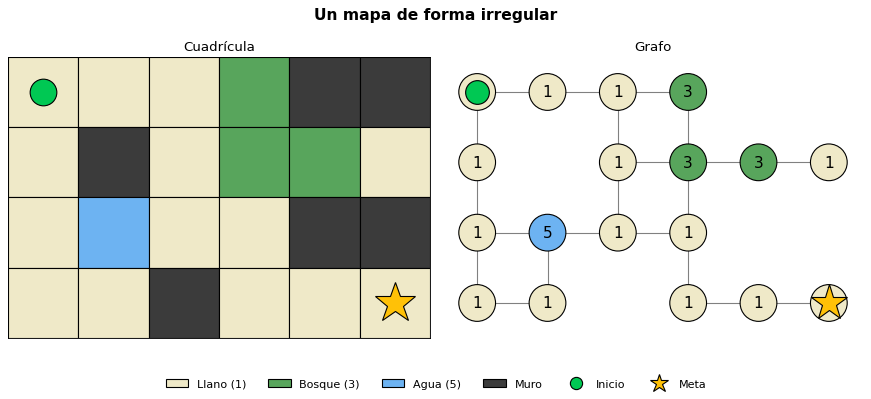

In [6]:
ejemplo = leer_mapa("""
I..B
.#.BB.
.A..
..#..M
""")

print('Tamaño:', ejemplo['filas'], 'filas por', ejemplo['columnas'], 'columnas')
print('Inicio:', ejemplo['inicio'], '  Meta:', ejemplo['meta'])
print('Vecinos del inicio:', vecinos(ejemplo, ejemplo['inicio']))
print('Vecinos de (2, 2): ', vecinos(ejemplo, (2, 2)))

mostrar_mapa(ejemplo, 'Un mapa de forma irregular')

## 2. Los cinco algoritmos

Los cinco siguen el mismo esquema:

1. Hay una estructura con las casillas **pendientes**. Al principio solo tiene el inicio.
2. Se saca una casilla de la estructura. Esa casilla queda **explorada**.
3. Si es la meta, se terminó.
4. Si no, sus vecinas entran a la estructura.
5. Se repite desde el paso 2 hasta llegar a la meta o hasta que la estructura quede vacía (no hay ruta).

**Lo único que cambia de un algoritmo a otro es qué casilla sale primero de la estructura.**

Todos devuelven lo mismo: la ruta encontrada (o `None` si no hay) y la lista de casillas exploradas, en el orden en que se exploraron.

Para poder reconstruir la ruta, cada algoritmo anota en el diccionario `padres` desde qué casilla llegó a cada una. Al terminar, se camina hacia atrás desde la meta hasta el inicio.

In [7]:
def reconstruir_ruta(padres, meta):
    """Arma la ruta caminando hacia atrás desde la meta.

    Entradas:
        padres: diccionario {casilla: casilla desde la que se llegó a ella}.
                El inicio tiene como padre None.
        meta:   la casilla donde termina la ruta

    Salida: lista de casillas desde el inicio hasta la meta.
    """
    ruta = []
    casilla = meta
    while casilla is not None:        # el padre del inicio es None: ahí se detiene
        ruta.append(casilla)
        casilla = padres[casilla]     # se retrocede a la casilla desde la que se llegó
    ruta.reverse()                    # se armó de la meta al inicio; se voltea
    return ruta


def estimacion(casilla, meta):
    """Estima cuánto falta para llegar a la meta: la distancia en casillas, sin diagonales.

    Entradas:
        casilla: la posición (fila, columna) desde la que se mide
        meta:    la posición (fila, columna) de la meta

    Salida: un número entero. Es cuántas filas faltan más cuántas columnas faltan.
            No se fija en muros ni en terrenos.

    La usan el voraz y A* para adivinar qué casilla está más cerca de la meta.
    """
    filas_que_faltan = abs(casilla[0] - meta[0])       # abs quita el signo: da igual arriba o abajo
    columnas_que_faltan = abs(casilla[1] - meta[1])
    return filas_que_faltan + columnas_que_faltan

### BFS: búsqueda en anchura

Usa una **cola**: la primera casilla que entra es la primera que sale. Así explora por capas: primero todo lo que está a 1 paso del inicio, luego todo lo que está a 2 pasos, y así.

- Encuentra la ruta con **menos pasos**.
- No se fija en los costos, así que esa ruta puede salir cara.

In [8]:
def bfs(mapa, inicio, meta):
    """Búsqueda en anchura (BFS): explora por capas alrededor del inicio.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        inicio: la casilla (fila, columna) de donde se sale
        meta:   la casilla (fila, columna) a la que se quiere llegar

    Salida: el par (ruta, exploradas).
        ruta:       lista de casillas del inicio a la meta, o None si no hay camino
        exploradas: lista de las casillas que salieron de la cola, en orden

    Garantía: la ruta tiene la menor cantidad de pasos posible. No toma en cuenta los costos.
    """
    cola = deque([inicio])               # casillas pendientes, en orden de llegada
    padres = {inicio: None}              # desde dónde se llegó a cada casilla; también dice cuáles ya se descubrieron
    exploradas = []

    while cola:                          # mientras queden casillas pendientes
        actual = cola.popleft()          # sale la que lleva más tiempo esperando
        exploradas.append(actual)
        if actual == meta:               # se llegó: se arma la ruta y se termina
            return reconstruir_ruta(padres, meta), exploradas
        for vecina, costo in vecinos(mapa, actual):
            if vecina not in padres:     # solo las que no se habían descubierto
                padres[vecina] = actual  # se anota que a la vecina se llegó desde la actual
                cola.append(vecina)      # entra al final de la cola

    return None, exploradas              # la cola se vació sin llegar a la meta: no hay camino

### DFS: búsqueda en profundidad

Usa una **pila**: la última casilla que entra es la primera que sale. Así se lanza por un camino hasta el fondo y solo regresa cuando ya no puede avanzar.

- Encuentra **alguna** ruta, sin ninguna garantía: suele ser larga y cara.

In [9]:
def dfs(mapa, inicio, meta):
    """Búsqueda en profundidad (DFS): sigue un camino hasta el fondo antes de probar otro.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        inicio: la casilla (fila, columna) de donde se sale
        meta:   la casilla (fila, columna) a la que se quiere llegar

    Salida: el par (ruta, exploradas).
        ruta:       lista de casillas del inicio a la meta, o None si no hay camino
        exploradas: lista de las casillas que salieron de la pila, en orden

    Garantía: ninguna sobre la ruta. Si hay camino lo encuentra, pero puede ser largo y caro.
    """
    pila = [inicio]                      # casillas pendientes; la última de la lista es la de arriba
    padres = {inicio: None}              # desde dónde se llegó a cada casilla
    exploradas = []
    vistas = set()                       # casillas ya exploradas

    while pila:                          # mientras queden casillas pendientes
        actual = pila.pop()              # sale la última que entró
        if actual in vistas:             # una casilla puede estar repetida en la pila: se ignora
            continue
        vistas.add(actual)
        exploradas.append(actual)
        if actual == meta:               # se llegó: se arma la ruta y se termina
            return reconstruir_ruta(padres, meta), exploradas
        # Se meten al revés para que la primera en salir sea la de arriba,
        # luego derecha, abajo e izquierda.
        for vecina, costo in reversed(vecinos(mapa, actual)):
            if vecina not in vistas:
                padres[vecina] = actual  # se anota que a la vecina se llegó desde la actual
                pila.append(vecina)      # entra arriba de la pila

    return None, exploradas              # la pila se vació sin llegar a la meta: no hay camino

### Dijkstra

Usa una **cola de prioridad**: siempre sale la casilla a la que se puede llegar con el **menor costo acumulado** desde el inicio.

- Encuentra la ruta de **menor costo**.
- Explora en todas direcciones, porque no sabe hacia dónde está la meta.

Cada elemento de la cola es un par `(costo, casilla)`. Python compara los pares empezando por el primer dato, así que sale primero el de menor costo.

In [10]:
def dijkstra(mapa, inicio, meta):
    """Algoritmo de Dijkstra: explora siempre la casilla más barata de alcanzar desde el inicio.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        inicio: la casilla (fila, columna) de donde se sale
        meta:   la casilla (fila, columna) a la que se quiere llegar

    Salida: el par (ruta, exploradas).
        ruta:       lista de casillas del inicio a la meta, o None si no hay camino
        exploradas: lista de las casillas que salieron de la cola, en orden

    Garantía: la ruta tiene el menor costo posible.
    """
    cola = [(0, inicio)]                 # cola de prioridad con pares (costo acumulado, casilla)
    costos = {inicio: 0}                 # el menor costo conocido para llegar a cada casilla
    padres = {inicio: None}              # desde dónde se llegó a cada casilla
    exploradas = []
    vistas = set()                       # casillas ya exploradas

    while cola:                          # mientras queden casillas pendientes
        costo, actual = heapq.heappop(cola)      # sale la de menor costo acumulado
        if actual in vistas:                     # ya se había explorado con un costo menor: se ignora
            continue
        vistas.add(actual)
        exploradas.append(actual)
        if actual == meta:                       # se llegó: se arma la ruta y se termina
            return reconstruir_ruta(padres, meta), exploradas
        for vecina, paso in vecinos(mapa, actual):
            nuevo = costo + paso                 # costo de llegar a la vecina pasando por la actual
            if vecina not in costos or nuevo < costos[vecina]:
                costos[vecina] = nuevo           # es la forma más barata de llegar que se conoce
                padres[vecina] = actual          # y se llega desde la actual
                heapq.heappush(cola, (nuevo, vecina))

    return None, exploradas              # la cola se vació sin llegar a la meta: no hay camino

### Búsqueda voraz

Usa una cola de prioridad, pero ordenada solo por la **estimación**: siempre sale la casilla que parece más cerca de la meta.

- Suele explorar muy poco, porque va directo hacia la meta.
- No se fija en lo que ya gastó, así que puede meterse por terreno caro o dar rodeos al toparse con un muro. **No garantiza la ruta más barata.**

In [11]:
def voraz(mapa, inicio, meta):
    """Búsqueda voraz: explora siempre la casilla que parece más cerca de la meta.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        inicio: la casilla (fila, columna) de donde se sale
        meta:   la casilla (fila, columna) a la que se quiere llegar

    Salida: el par (ruta, exploradas).
        ruta:       lista de casillas del inicio a la meta, o None si no hay camino
        exploradas: lista de las casillas que salieron de la cola, en orden

    Garantía: ninguna sobre la ruta. Suele explorar muy poco, pero no toma en cuenta los costos.
    """
    cola = [(estimacion(inicio, meta), inicio)]  # cola de prioridad con pares (estimación hasta la meta, casilla)
    padres = {inicio: None}              # desde dónde se llegó a cada casilla; también dice cuáles ya se descubrieron
    exploradas = []

    while cola:                          # mientras queden casillas pendientes
        distancia, actual = heapq.heappop(cola)  # sale la que parece más cerca de la meta
        exploradas.append(actual)
        if actual == meta:                       # se llegó: se arma la ruta y se termina
            return reconstruir_ruta(padres, meta), exploradas
        for vecina, costo in vecinos(mapa, actual):
            if vecina not in padres:             # solo las que no se habían descubierto
                padres[vecina] = actual
                # La prioridad es solo la estimación: el costo del terreno no se usa para nada.
                heapq.heappush(cola, (estimacion(vecina, meta), vecina))

    return None, exploradas              # la cola se vació sin llegar a la meta: no hay camino

### A\*

Combina a Dijkstra con el voraz. La prioridad de cada casilla es:

**prioridad = costo acumulado desde el inicio + estimación hasta la meta**

Es decir, lo que ya se gastó más lo que se cree que falta. Ese total es una estimación de lo que costaría la ruta completa pasando por esa casilla.

- Encuentra la ruta de **menor costo**, igual que Dijkstra.
- Explora menos, porque la estimación lo orienta hacia la meta.

Cada elemento de la cola es `(prioridad, estimación, casilla)`. El segundo dato sirve para los empates: entre dos casillas con la misma prioridad, sale primero la que parece más cerca de la meta.

**Sobre los empates.** Esa regla no cambia el costo de la ruta, que sigue siendo el mínimo. Lo que sí cambia es cuántas casillas se exploran: entre casillas igual de prometedoras, preferir la más cercana a la meta evita revisar muchas de las otras. Con otra regla de desempate, el costo sería el mismo y el número de casillas exploradas podría salir distinto.

In [12]:
def a_estrella(mapa, inicio, meta):
    """Algoritmo A*: explora la casilla con menor suma de lo ya gastado más lo que se estima que falta.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        inicio: la casilla (fila, columna) de donde se sale
        meta:   la casilla (fila, columna) a la que se quiere llegar

    Salida: el par (ruta, exploradas).
        ruta:       lista de casillas del inicio a la meta, o None si no hay camino
        exploradas: lista de las casillas que salieron de la cola, en orden

    Garantía: la ruta tiene el menor costo posible, porque la estimación nunca se pasa del costo real.
    """
    distancia = estimacion(inicio, meta)
    cola = [(distancia, distancia, inicio)]      # cola de prioridad con (costo acumulado + estimación, estimación, casilla)
    costos = {inicio: 0}                         # el menor costo conocido para llegar a cada casilla
    padres = {inicio: None}                      # desde dónde se llegó a cada casilla
    exploradas = []
    vistas = set()                               # casillas ya exploradas

    while cola:                                  # mientras queden casillas pendientes
        prioridad, distancia, actual = heapq.heappop(cola)   # sale la de menor prioridad
        if actual in vistas:                     # ya se había explorado por un camino mejor: se ignora
            continue
        vistas.add(actual)
        exploradas.append(actual)
        if actual == meta:                       # se llegó: se arma la ruta y se termina
            return reconstruir_ruta(padres, meta), exploradas
        for vecina, paso in vecinos(mapa, actual):
            nuevo = costos[actual] + paso        # lo gastado para llegar a la vecina pasando por la actual
            if vecina not in costos or nuevo < costos[vecina]:
                costos[vecina] = nuevo           # es la forma más barata de llegar que se conoce
                padres[vecina] = actual
                distancia = estimacion(vecina, meta)         # lo que se cree que falta desde la vecina
                # Prioridad = lo gastado + lo que falta. La estimación sola va después para los empates.
                heapq.heappush(cola, (nuevo + distancia, distancia, vecina))

    return None, exploradas                      # la cola se vació sin llegar a la meta: no hay camino

## 3. Medir y comprobar

`comparar` corre los cinco algoritmos sobre un mapa y calcula las tres medidas de cada uno. `comprobar` usa NetworkX como referencia independiente para confirmar que los algoritmos hechos a mano dan resultados correctos:

- Todas las rutas son válidas: empiezan en el inicio, terminan en la meta y cada paso une dos casillas vecinas.
- El costo de Dijkstra y de A\* es el mínimo que calcula NetworkX.
- Los pasos de BFS son el mínimo que calcula NetworkX.
- Si NetworkX dice que no hay camino, ningún algoritmo encontró ruta.

**Por qué se revisa eso y no otra cosa.** A cada algoritmo se le exige solo lo que promete. Una ruta válida se le exige a los cinco, porque una ruta que atraviesa un muro o da un salto no sirve aunque llegue a la meta. El costo mínimo se le exige a Dijkstra y a A\*, y el mínimo de pasos a BFS, porque esas son sus garantías. DFS y el voraz solo se revisan por validez: ninguno de los dos promete una ruta óptima, así que una ruta larga o cara no es un error en ellos.

In [13]:
# Los cinco algoritmos con su nombre, para poder recorrerlos todos con un ciclo.
ALGORITMOS = {'BFS': bfs, 'DFS': dfs, 'Dijkstra': dijkstra, 'Voraz': voraz, 'A*': a_estrella}


def medir(mapa, ruta):
    """Calcula los pasos y el costo de una ruta.

    Entradas:
        mapa: el diccionario que devuelve leer_mapa
        ruta: lista de casillas, del inicio a la meta

    Salida: el par (pasos, costo).
        pasos: cuántos movimientos tiene la ruta
        costo: la suma de lo que cuesta entrar a cada casilla
    """
    pasos = len(ruta) - 1             # una ruta de n casillas tiene n - 1 movimientos
    # ruta[1:] deja fuera la primera casilla: el inicio no se cobra porque no se entra a él.
    costo = sum(COSTOS[mapa['terreno'][casilla]] for casilla in ruta[1:])
    return pasos, costo


def comparar(mapa):
    """Corre los cinco algoritmos del inicio a la meta del mapa y mide a cada uno.

    Entrada: el diccionario que devuelve leer_mapa.

    Salida: diccionario {nombre del algoritmo: resultado}. Cada resultado es un diccionario con
        'ruta':       la ruta que encontró, o None
        'exploradas': las casillas que exploró, en orden
        'pasos':      los pasos de su ruta, o None si no encontró
        'costo':      el costo de su ruta, o None si no encontró
    """
    resultados = {}
    for nombre, algoritmo in ALGORITMOS.items():
        ruta, exploradas = algoritmo(mapa, mapa['inicio'], mapa['meta'])
        pasos, costo = medir(mapa, ruta) if ruta else (None, None)   # sin ruta no hay nada que medir
        resultados[nombre] = {'ruta': ruta, 'exploradas': exploradas, 'pasos': pasos, 'costo': costo}
    return resultados


def imprimir_tabla(resultados):
    """Imprime la tabla comparativa: casillas exploradas, pasos y costo de cada algoritmo.

    Entrada: el diccionario que devuelve comparar.
    No devuelve nada: imprime la tabla. Marca con una nota las rutas de costo mínimo.
    """
    # El menor costo entre los algoritmos que sí encontraron ruta.
    costos = [r['costo'] for r in resultados.values() if r['costo'] is not None]
    minimo = min(costos) if costos else None

    # En los formatos, <10 alinea a la izquierda en 10 espacios y >8 a la derecha en 8.
    print(f"{'Algoritmo':<10}{'Exploradas':>11}{'Pasos':>8}{'Costo':>8}   Nota")
    print('-' * 52)
    for nombre, r in resultados.items():
        if r['ruta'] is None:
            print(f"{nombre:<10}{len(r['exploradas']):>11}{'-':>8}{'-':>8}   sin ruta")
        else:
            nota = 'costo mínimo' if r['costo'] == minimo else ''
            print(f"{nombre:<10}{len(r['exploradas']):>11}{r['pasos']:>8}{r['costo']:>8}   {nota}")


def comprobar(mapa, resultados):
    """Compara los resultados hechos a mano contra NetworkX.

    Entradas:
        mapa:       el diccionario que devuelve leer_mapa
        resultados: el diccionario que devuelve comparar

    No devuelve nada: imprime lo que comprobó. Si algo no coincide, assert detiene
    la ejecución con un error.
    """
    grafo = construir_grafo(mapa)
    inicio, meta = mapa['inicio'], mapa['meta']

    # Caso sin camino: NetworkX dice que no existe y nadie debió encontrar ruta.
    if not nx.has_path(grafo, inicio, meta):
        assert all(r['ruta'] is None for r in resultados.values())
        print('Comprobado con NetworkX: no existe camino y ningún algoritmo encontró ruta.')
        return

    # Toda ruta debe empezar en el inicio, terminar en la meta y seguir aristas del grafo.
    for nombre, r in resultados.items():
        ruta = r['ruta']
        # Si existe camino, todos los algoritmos deben encontrar alguna ruta.
        assert ruta is not None, f'{nombre} no devolvió ninguna ruta, pero NetworkX dice que sí existe camino.'
        assert ruta[0] == inicio and ruta[-1] == meta, nombre
        assert nx.is_path(grafo, ruta), nombre

    # Los valores de referencia, calculados por NetworkX.
    costo_minimo = nx.dijkstra_path_length(grafo, inicio, meta)      # usa el peso de las aristas
    pasos_minimos = nx.shortest_path_length(grafo, inicio, meta)     # sin pesos: cuenta aristas
    assert resultados['Dijkstra']['costo'] == costo_minimo
    assert resultados['A*']['costo'] == costo_minimo
    assert resultados['BFS']['pasos'] == pasos_minimos
    print(f'Comprobado con NetworkX: rutas válidas, costo mínimo = {costo_minimo}, '
          f'pasos mínimos = {pasos_minimos}.')


def mostrar_busquedas(mapa, resultados):
    """Dibuja el resultado de cada algoritmo, un renglón por algoritmo: cuadrícula y grafo.

    Entradas:
        mapa:       el diccionario que devuelve leer_mapa
        resultados: el diccionario que devuelve comparar

    No devuelve nada: muestra la figura.
    """
    alto = 5.5 * mapa['filas'] / mapa['columnas'] + 0.6          # alto de cada renglón de dibujos
    # Una figura con un renglón por algoritmo y 2 columnas. 'ejes' es una tabla de ejes:
    # cada renglón trae el eje de la cuadrícula y el eje del grafo.
    figura, ejes = plt.subplots(len(resultados), 2, figsize=(11, alto * len(resultados)))

    # zip empareja cada renglón de ejes con el resultado de un algoritmo.
    for (izquierda, derecha), (nombre, r) in zip(ejes, resultados.items()):
        dibujar_cuadricula(izquierda, mapa, r['ruta'], r['exploradas'])
        dibujar_grafo(derecha, mapa, r['ruta'], r['exploradas'])
        # El título de cada renglón lleva las tres medidas del algoritmo.
        if r['ruta'] is None:
            medidas = f"{len(r['exploradas'])} exploradas, sin ruta"
        else:
            medidas = f"{len(r['exploradas'])} exploradas, {r['pasos']} pasos, costo {r['costo']}"
        izquierda.set_title(f'{nombre}: {medidas}', fontweight='bold')
        derecha.set_title(f'Grafo de {nombre}')

    figura.tight_layout()                # acomoda los renglones sin que se encimen
    plt.show()


def analizar(mapa, titulo):
    """Hace el análisis completo de un mapa.

    Muestra el mapa, compara los cinco algoritmos, imprime la tabla, comprueba
    con NetworkX y dibuja cada búsqueda.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        titulo: texto para el título de la figura del mapa

    Salida: el diccionario que devuelve comparar, por si se quiere usar después.
    """
    mostrar_mapa(mapa, titulo)
    resultados = comparar(mapa)
    imprimir_tabla(resultados)
    comprobar(mapa, resultados)
    mostrar_busquedas(mapa, resultados)
    return resultados

## 4. Comparación en cuatro mapas

Cada mapa está pensado para que se note algo distinto.

### Mapa 1: campo abierto

Todo es llano, así que cada paso cuesta 1 y la ruta con menos pasos es también la más barata.

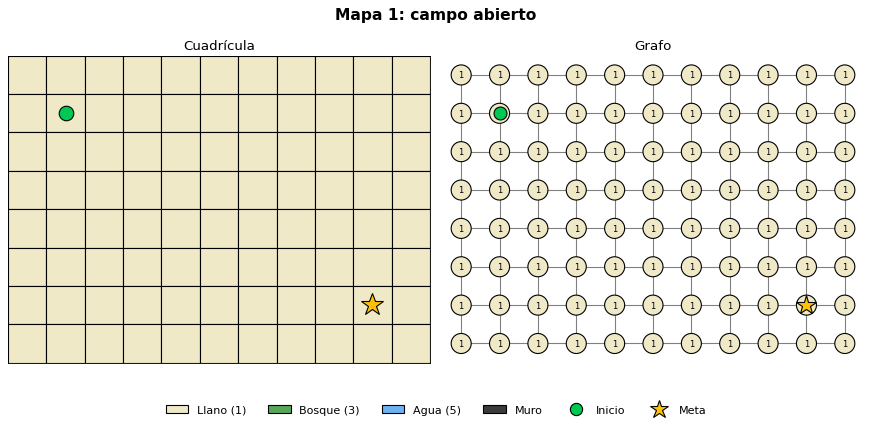

Algoritmo  Exploradas   Pasos   Costo   Nota
----------------------------------------------------
BFS                84      13      13   costo mínimo
DFS                20      19      19   
Dijkstra           84      13      13   costo mínimo
Voraz              14      13      13   costo mínimo
A*                 14      13      13   costo mínimo
Comprobado con NetworkX: rutas válidas, costo mínimo = 13, pasos mínimos = 13.


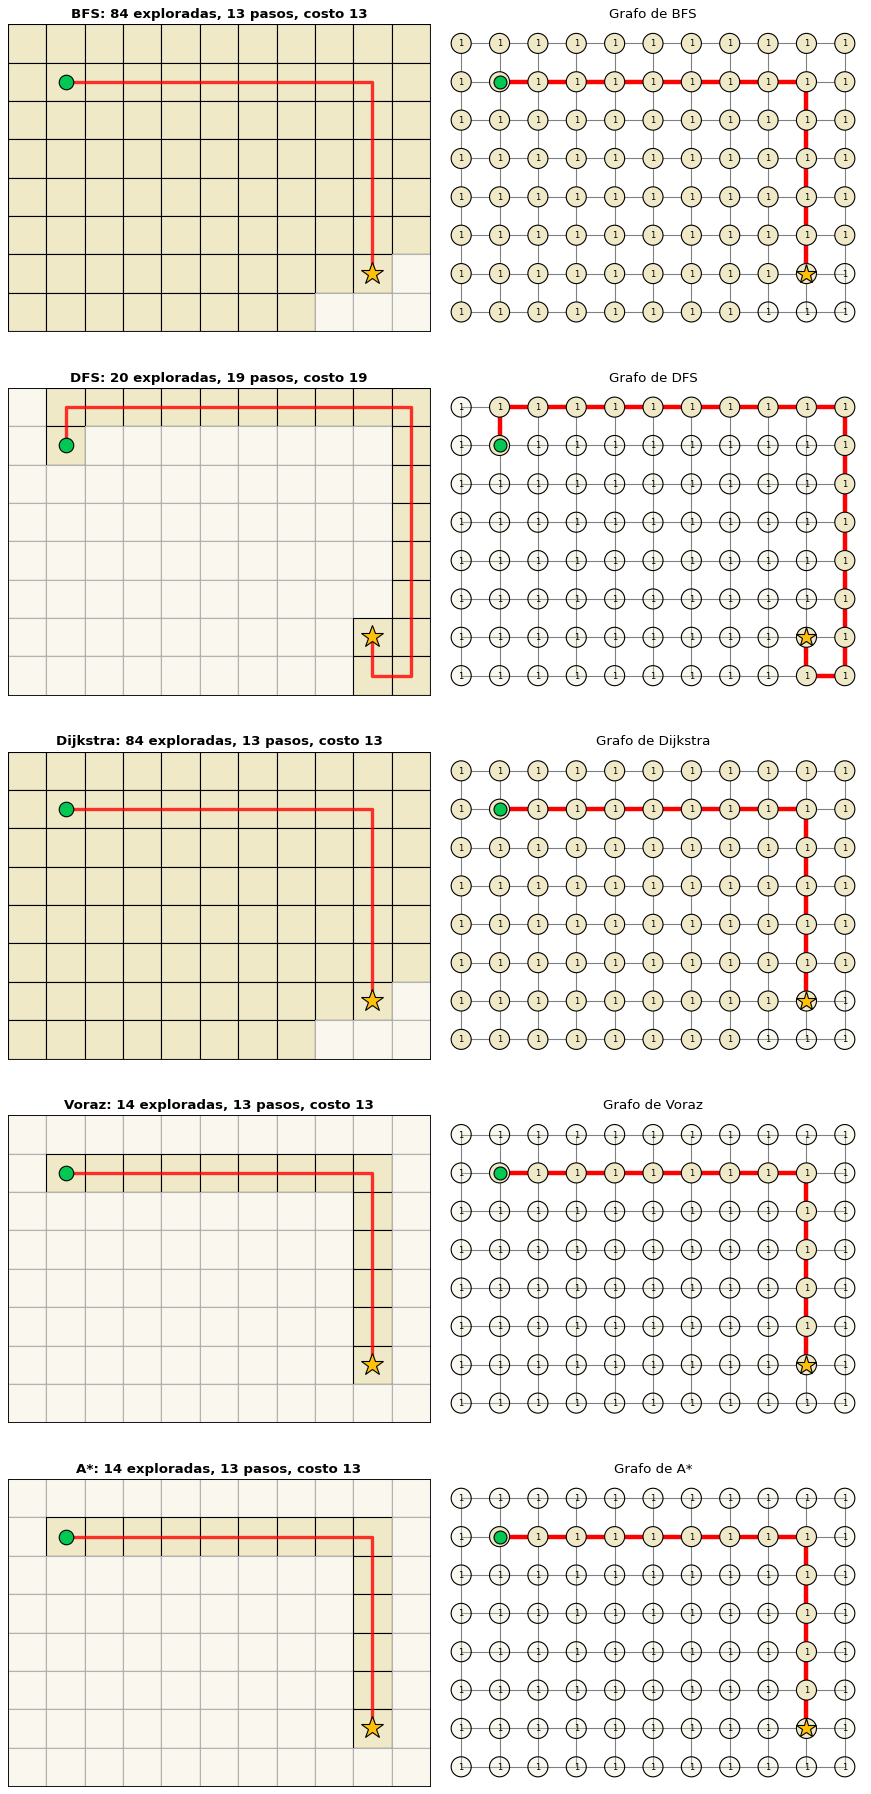

In [14]:
mapa_abierto = leer_mapa("""
...........
.I.........
...........
...........
...........
...........
.........M.
...........
""")

resultados_abierto = analizar(mapa_abierto, 'Mapa 1: campo abierto')

**Qué se observa**

- BFS, Dijkstra, el voraz y A\* encuentran una ruta de 13 pasos y costo 13, que es lo mínimo posible.
- BFS y Dijkstra exploran 84 de las 88 casillas. Como todo cuesta 1, los dos avanzan en capas parejas alrededor del inicio, sin saber hacia dónde está la meta.
- El voraz y A\* exploran solo 14 casillas: exactamente las de la ruta. La estimación los lleva directo.
- DFS explora pocas casillas, pero su ruta es la peor: 19 pasos. Se va por el primer camino que encuentra y lo sigue hasta el fondo, sin importar si se aleja.

### Mapa 2: terrenos mezclados

Entre el inicio y la meta hay un lago y un bosque. El camino recto es corto en pasos, pero caro. Rodear es más largo, pero barato.

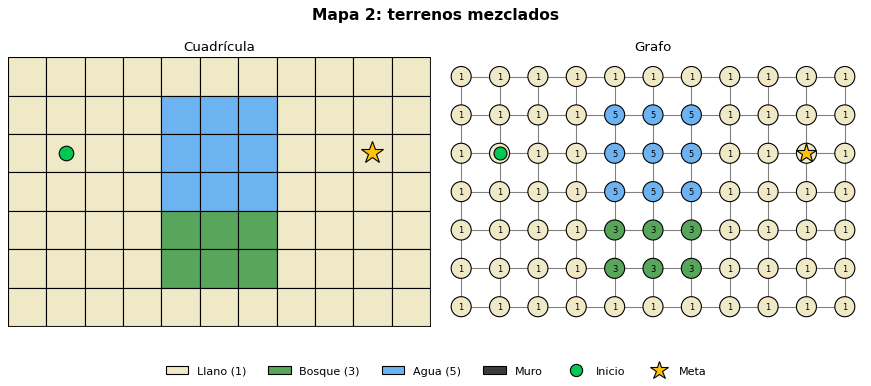

Algoritmo  Exploradas   Pasos   Costo   Nota
----------------------------------------------------
BFS                53       8      20   
DFS                23      22      22   
Dijkstra           59      12      12   costo mínimo
Voraz               9       8      20   
A*                 20      12      12   costo mínimo
Comprobado con NetworkX: rutas válidas, costo mínimo = 12, pasos mínimos = 8.


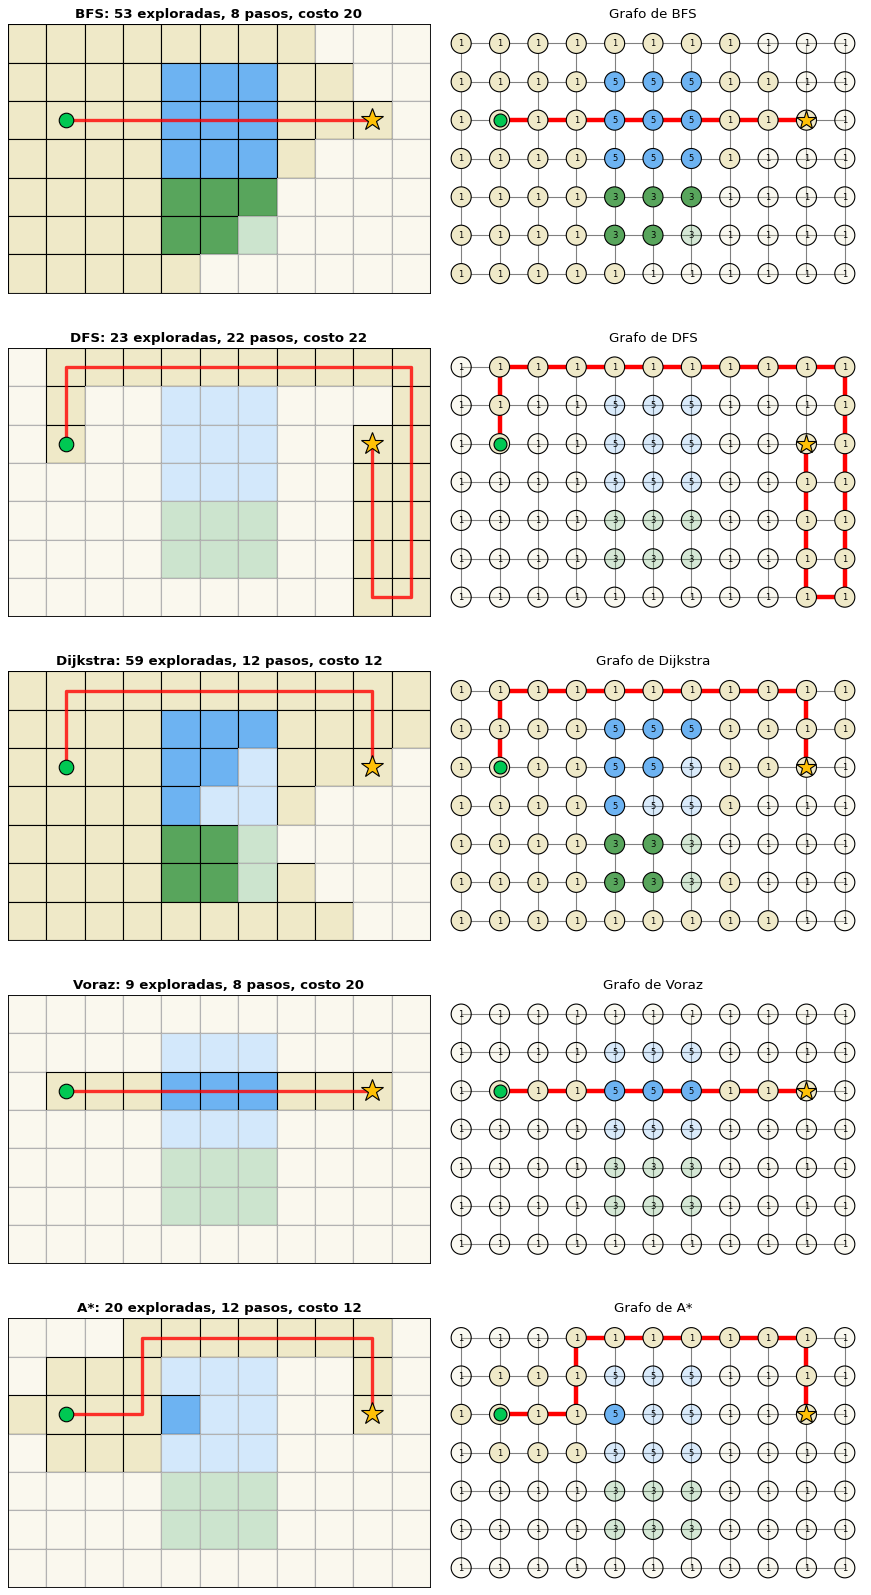

In [15]:
mapa_terrenos = leer_mapa("""
...........
....AAA....
.I..AAA..M.
....AAA....
....BBB....
....BBB....
...........
""")

resultados_terrenos = analizar(mapa_terrenos, 'Mapa 2: terrenos mezclados')

**Qué se observa**

- BFS y el voraz cruzan el lago: 8 pasos, pero costo 20. Es la ruta con menos pasos y no es la más barata.
- Dijkstra y A\* rodean el lago: 12 pasos y costo 12. Dan más pasos y gastan menos.
- **Menos pasos no significa menos costo.** En cuanto los terrenos cuestan distinto, BFS deja de ser confiable.
- Dijkstra explora 59 casillas y A\* solo 20 para llegar a la misma ruta.
- El voraz es el que menos explora (9 casillas), y aun así se equivoca: rápido no es lo mismo que correcto.

### Mapa 3: laberinto

Pasillos de llano entre muros, con callejones sin salida y más de un camino hasta la meta.

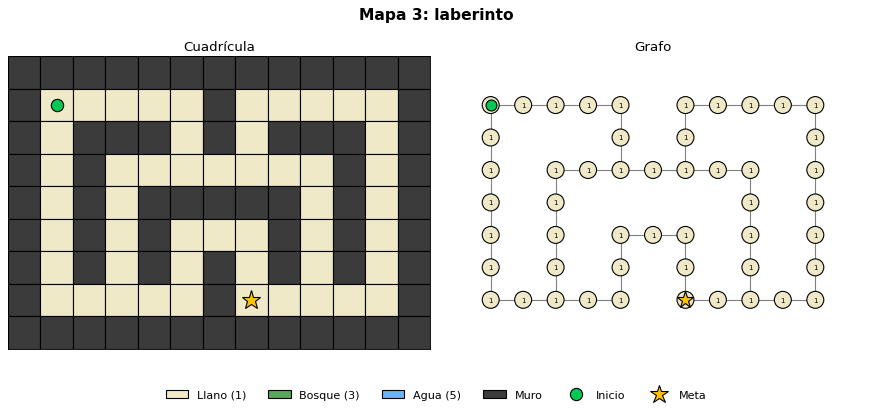

Algoritmo  Exploradas   Pasos   Costo   Nota
----------------------------------------------------
BFS                47      16      16   costo mínimo
DFS                30      24      24   
Dijkstra           46      16      16   costo mínimo
Voraz              19      16      16   costo mínimo
A*                 29      16      16   costo mínimo
Comprobado con NetworkX: rutas válidas, costo mínimo = 16, pasos mínimos = 16.


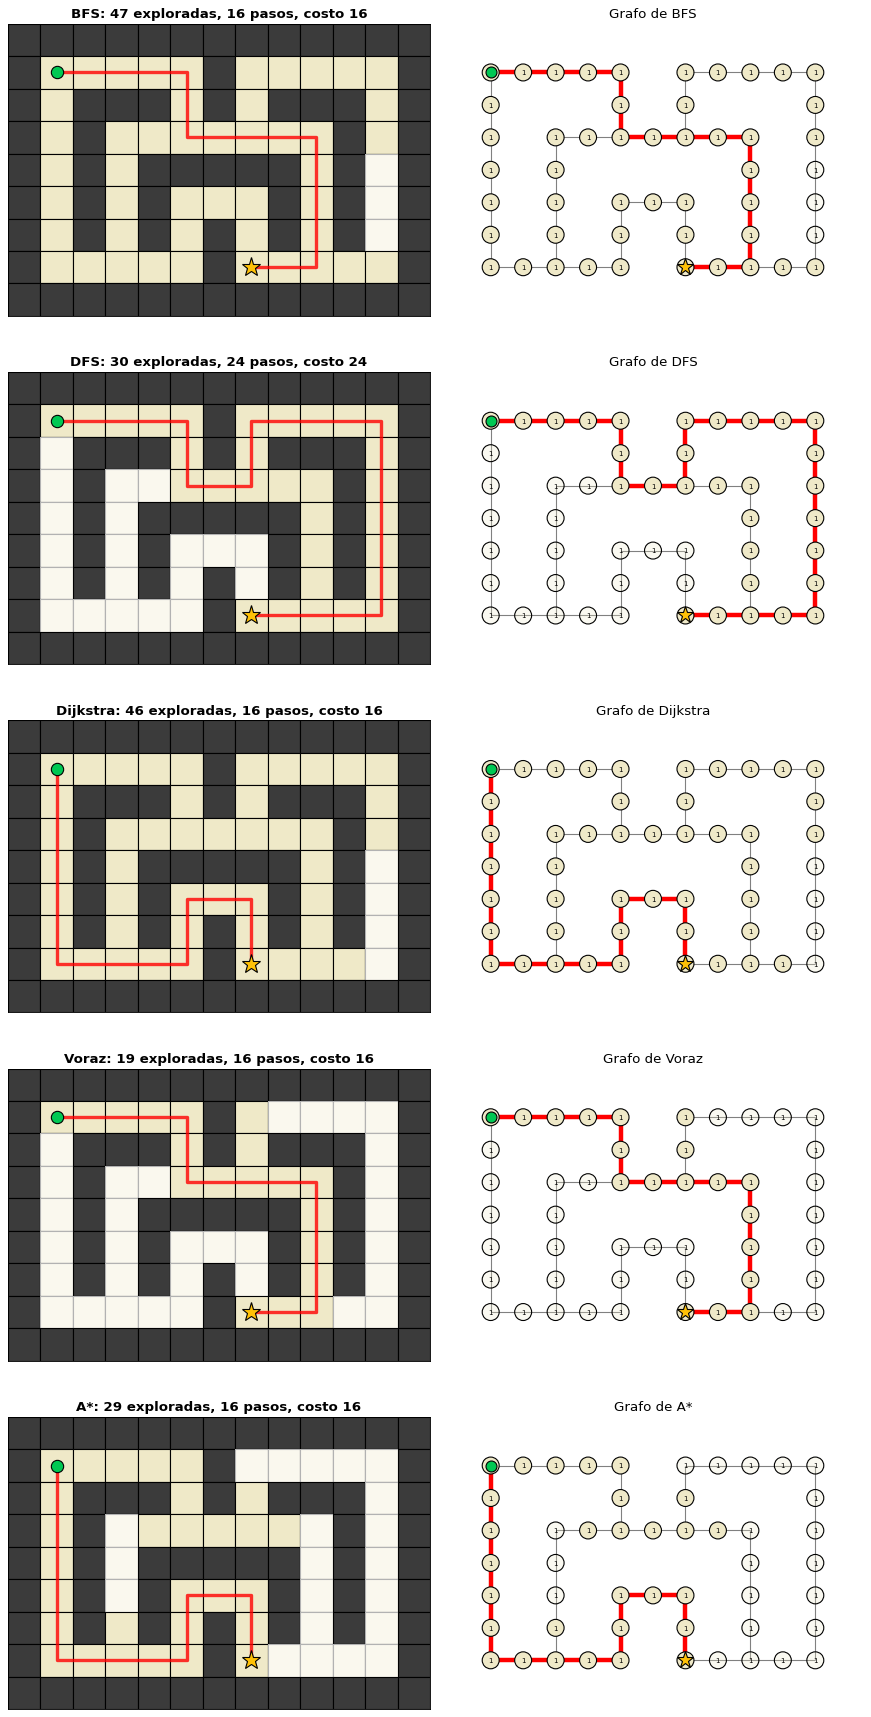

In [16]:
mapa_laberinto = leer_mapa("""
#############
#I....#.....#
#.###.#.###.#
#.#.......#.#
#.#.#####.#.#
#.#.#...#.#.#
#.#.#.#.#.#.#
#.....#M....#
#############
""")

resultados_laberinto = analizar(mapa_laberinto, 'Mapa 3: laberinto')

**Qué se observa**

- Como todo es llano, aquí los pasos y el costo coinciden.
- BFS, Dijkstra, el voraz y A\* encuentran rutas de 16 pasos, que es lo mínimo. Hay dos rutas distintas de 16 pasos y no todos eligen la misma: empatan en costo, así que las dos son igual de buenas.
- DFS se va por el primer pasillo que encuentra y termina con una ruta larga: 24 pasos.
- A\* explora 29 casillas y Dijkstra 46. La ventaja de A\* es menor que en el campo abierto, porque en un laberinto los muros obligan a alejarse de la meta y la estimación orienta menos.
- El voraz acierta en este laberinto explorando poco, pero no hay garantía de que lo haga en otro.

### Mapa 4: sin solución

La meta está encerrada entre muros. En el grafo se ve como un vértice aislado: no tiene ninguna arista, así que no existe camino hacia él.

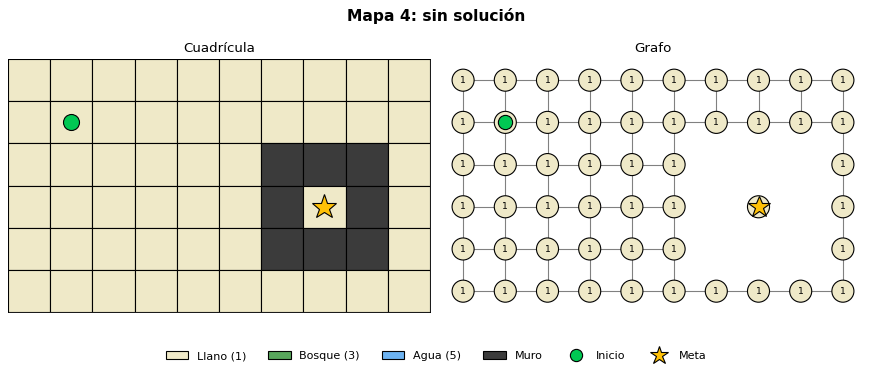

Algoritmo  Exploradas   Pasos   Costo   Nota
----------------------------------------------------
BFS                51       -       -   sin ruta
DFS                51       -       -   sin ruta
Dijkstra           51       -       -   sin ruta
Voraz              51       -       -   sin ruta
A*                 51       -       -   sin ruta
Comprobado con NetworkX: no existe camino y ningún algoritmo encontró ruta.


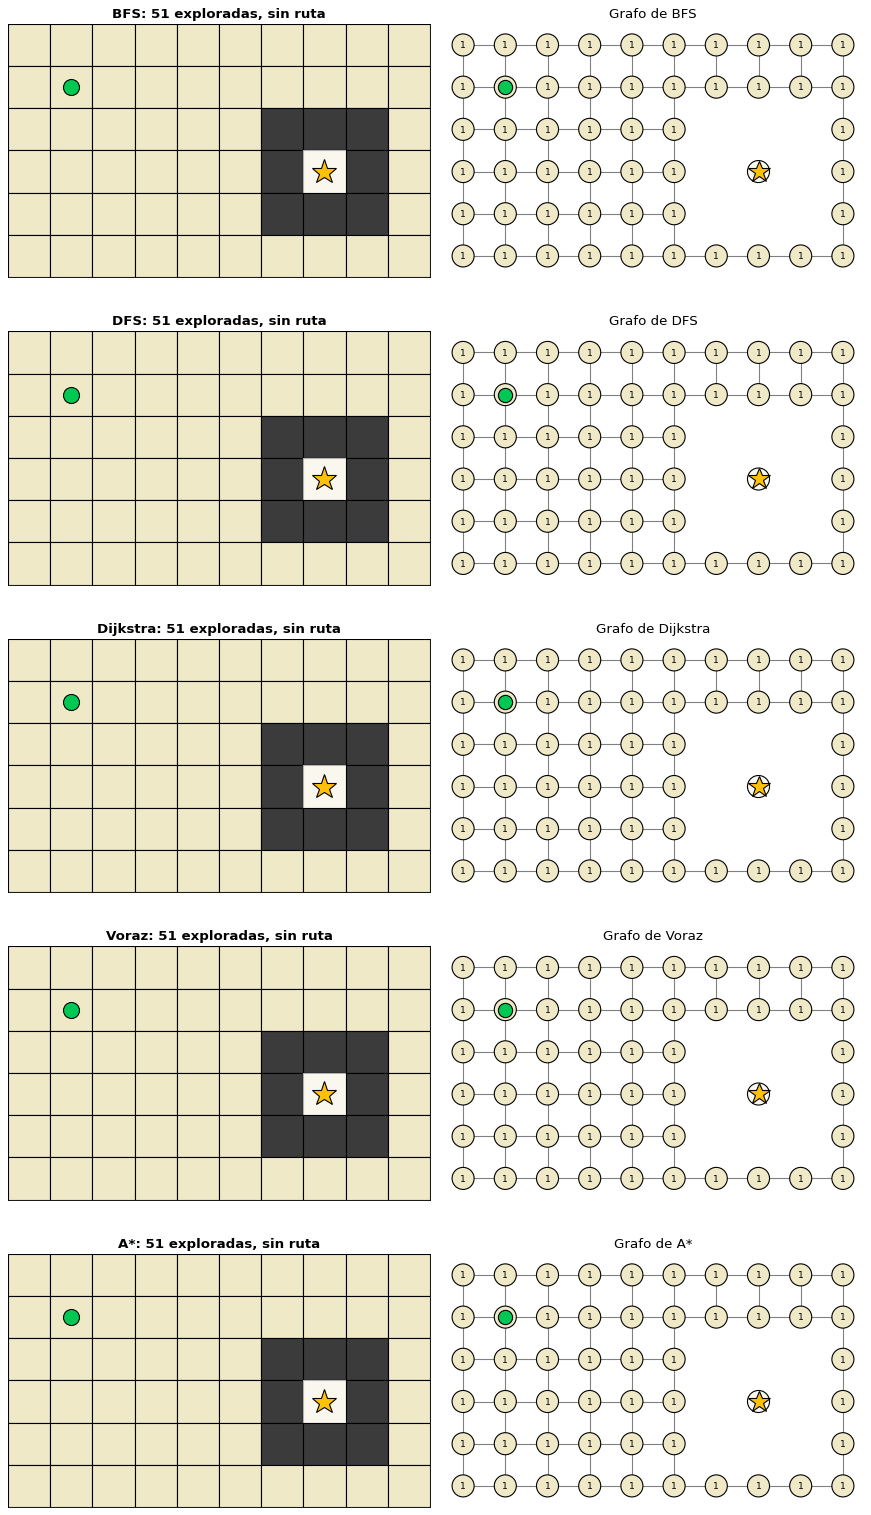

In [17]:
mapa_sin_solucion = leer_mapa("""
..........
.I........
......###.
......#M#.
......###.
..........
""")

resultados_sin_solucion = analizar(mapa_sin_solucion, 'Mapa 4: sin solución')

**Qué se observa**

- Los cinco algoritmos exploran las mismas 51 casillas: todas las que se pueden alcanzar desde el inicio.
- Para estar seguro de que no hay camino hay que revisar todo lo alcanzable. Ningún algoritmo, por listo que sea, se lo puede ahorrar.
- Todos terminan igual: la estructura de pendientes se queda vacía y devuelven que no hay ruta.

### Resumen de los cuatro mapas

In [18]:
pruebas = {'Campo abierto': resultados_abierto, 'Terrenos mezclados': resultados_terrenos,
           'Laberinto': resultados_laberinto, 'Sin solución': resultados_sin_solucion}

# Una tabla con las casillas exploradas y otra con el costo: un renglón por mapa, una columna por algoritmo.
for medida, titulo in [('exploradas', 'Casillas exploradas'), ('costo', 'Costo de la ruta')]:
    print(titulo)
    print(f"{'Mapa':<20}" + ''.join(f'{nombre:>10}' for nombre in ALGORITMOS))
    print('-' * 70)
    for nombre_mapa, resultados in pruebas.items():
        renglon = f'{nombre_mapa:<20}'
        for r in resultados.values():
            if medida == 'exploradas':
                valor = len(r['exploradas'])
            else:
                valor = r['costo'] if r['costo'] is not None else '-'
            renglon += f'{valor:>10}'
        print(renglon)
    print()

Casillas exploradas
Mapa                       BFS       DFS  Dijkstra     Voraz        A*
----------------------------------------------------------------------
Campo abierto               84        20        84        14        14
Terrenos mezclados          53        23        59         9        20
Laberinto                   47        30        46        19        29
Sin solución                51        51        51        51        51

Costo de la ruta
Mapa                       BFS       DFS  Dijkstra     Voraz        A*
----------------------------------------------------------------------
Campo abierto               13        19        13        13        13
Terrenos mezclados          20        22        12        20        12
Laberinto                   16        24        16        16        16
Sin solución                 -         -         -         -         -



## 5. Por qué A\* no se equivoca

A\* y el voraz usan la misma estimación: la distancia en casillas hasta la meta, sin diagonales. Uno siempre encuentra la ruta más barata y el otro no. La diferencia está en cómo la usan.

**La estimación nunca se pasa del costo real.** Si a una casilla le faltan `d` casillas para llegar a la meta, cualquier camino necesita al menos `d` pasos, y cada paso cuesta al menos 1 (el llano, que es el terreno más barato). Entonces el costo real de lo que falta es siempre mayor o igual que `d`. Los muros y los terrenos caros solo pueden hacer que el costo real sea más grande, nunca más chico.

**Por eso A\* acierta.** La prioridad de A\* es lo ya gastado más la estimación de lo que falta. Como la estimación nunca exagera, esa prioridad nunca es mayor que el costo real de la mejor ruta que pasa por esa casilla. Cuando la meta sale de la cola con costo `C`, todas las casillas que siguen esperando tienen prioridad mayor o igual que `C`, y eso significa que cualquier ruta que pase por ellas costaría `C` o más. Ya no puede existir una ruta más barata.

**Por eso explora menos que Dijkstra.** Dijkstra ordena solo por lo ya gastado, así que explora todo lo que esté más barato que la meta, en cualquier dirección. A\* le suma lo que falta, y con eso las casillas que se alejan de la meta quedan al fondo de la cola y muchas nunca llegan a salir.

**Por eso el voraz sí se equivoca.** El voraz ordena solo por la estimación y no toma en cuenta lo ya gastado. Entrar a una casilla de agua le parece igual de bueno que entrar a una de llano si las dos están a la misma distancia de la meta.

La siguiente celda lo comprueba en los cuatro mapas: con NetworkX se calcula el costo real desde cada casilla hasta la meta y se compara con la estimación.

In [19]:
def comprobar_estimacion(mapa, nombre):
    """Revisa, casilla por casilla, que la estimación no sea mayor que el costo real hasta la meta.

    Entradas:
        mapa:   el diccionario que devuelve leer_mapa
        nombre: nombre del mapa, para identificar el renglón que se imprime

    No devuelve nada: imprime cuántas casillas revisó y en cuántas la estimación se pasa.
    """
    grafo = construir_grafo(mapa)
    # Costo real desde cada casilla hasta la meta. En lugar de calcular una ruta por casilla,
    # se voltean todas las aristas y se mide una sola vez saliendo de la meta.
    # El resultado es un diccionario {casilla: costo real hasta la meta}.
    reales = nx.single_source_dijkstra_path_length(grafo.reverse(), mapa['meta'])

    # Casillas donde la estimación exagera. Si la lista queda vacía, la estimación nunca se pasa.
    se_pasan = [c for c, real in reales.items() if estimacion(c, mapa['meta']) > real]

    inicio = mapa['inicio']
    real_inicio = reales.get(inicio, 'no hay camino')    # el inicio no aparece si no puede llegar a la meta
    print(f"{nombre:<20} casillas revisadas: {len(reales):>3}   se pasan: {len(se_pasan)}   "
          f"desde el inicio: estimación {estimacion(inicio, mapa['meta'])}, costo real {real_inicio}")


comprobar_estimacion(mapa_abierto, 'Campo abierto')
comprobar_estimacion(mapa_terrenos, 'Terrenos mezclados')
comprobar_estimacion(mapa_laberinto, 'Laberinto')
comprobar_estimacion(mapa_sin_solucion, 'Sin solución')

Campo abierto        casillas revisadas:  88   se pasan: 0   desde el inicio: estimación 13, costo real 13
Terrenos mezclados   casillas revisadas:  77   se pasan: 0   desde el inicio: estimación 8, costo real 12
Laberinto            casillas revisadas:  50   se pasan: 0   desde el inicio: estimación 12, costo real 16
Sin solución         casillas revisadas:   1   se pasan: 0   desde el inicio: estimación 8, costo real no hay camino


En ningún mapa hay una sola casilla donde la estimación se pase del costo real.

En el mapa de terrenos mezclados, por ejemplo, desde el inicio la estimación dice 8 y el costo real es 12. La estimación se quedó corta, y eso está permitido. Lo que no puede pasar es que exagere.

En el mapa sin solución solo se revisa una casilla, la propia meta, porque desde ninguna otra se puede llegar a ella.

## 6. Objetos que hay que recoger

Ahora hay objetos en el mapa y hay que pasar por todos antes de llegar a la meta. Un objeto se recoge al pisar su casilla. El problema ya no es solo encontrar una ruta, sino decidir **en qué orden** visitar los objetos.

### Un grafo dentro de otro

Para decidir el orden no hacen falta todas las casillas. Solo importan los puntos de interés: el inicio, los objetos y la meta. Con ellos se forma un grafo nuevo, mucho más pequeño:

- **Vértices:** el inicio, cada objeto y la meta.
- **Aristas:** hay una entre cada par de puntos. Por eso es un **grafo completo**.
- **Pesos:** el costo de la ruta más barata entre esos dos puntos en el mapa, calculada con Dijkstra.

Como el inicio, los objetos y la meta están todos sobre llano, ir de un punto a otro cuesta lo mismo que regresar, y basta una arista sin dirección entre cada par.

Elegir el orden de los objetos es elegir un camino en ese grafo completo que salga del inicio, pase por todos los objetos y termine en la meta.

In [20]:
def costos_entre_puntos(mapa):
    """Calcula con Dijkstra la ruta más barata entre cada par de puntos de interés.

    Los puntos de interés son el inicio, los objetos y la meta.

    Entrada: el diccionario que devuelve leer_mapa.

    Salida: diccionario {(a, b): (costo, ruta)} para cada par de puntos distintos.
            Son los pesos de las aristas del grafo completo.
            Si no hay camino entre dos puntos, su costo y su ruta son None.
    """
    puntos = [mapa['inicio']] + mapa['objetos'] + [mapa['meta']]
    tabla = {}
    for a in puntos:
        for b in puntos:
            if a != b:                                    # de un punto a sí mismo no hay nada que medir
                ruta, exploradas = dijkstra(mapa, a, b)   # la ruta más barata de a hasta b
                costo = medir(mapa, ruta)[1] if ruta else None   # medir da (pasos, costo): se toma el costo
                tabla[(a, b)] = (costo, ruta)
    return tabla


def costo_del_orden(mapa, tabla, orden):
    """Suma lo que cuesta ir del inicio a la meta visitando los objetos en un orden dado.

    Entradas:
        mapa:  el diccionario que devuelve leer_mapa
        tabla: el diccionario que devuelve costos_entre_puntos
        orden: lista de las casillas de los objetos, en el orden en que se visitan

    Salida: el costo total del recorrido.
    """
    paradas = [mapa['inicio']] + list(orden) + [mapa['meta']]
    # zip(paradas, paradas[1:]) da los tramos: cada parada con la que le sigue.
    return sum(tabla[(a, b)][0] for a, b in zip(paradas, paradas[1:]))


def unir_rutas(mapa, tabla, orden):
    """Pega las rutas de cada tramo para formar la ruta completa del inicio a la meta.

    Entradas:
        mapa:  el diccionario que devuelve leer_mapa
        tabla: el diccionario que devuelve costos_entre_puntos
        orden: lista de las casillas de los objetos, en el orden en que se visitan

    Salida: lista de casillas de todo el recorrido.
    """
    paradas = [mapa['inicio']] + list(orden) + [mapa['meta']]
    ruta = [mapa['inicio']]
    for a, b in zip(paradas, paradas[1:]):
        ruta += tabla[(a, b)][1][1:]      # la ruta del tramo sin su primera casilla, que ya está puesta
    return ruta

### Dos estrategias para elegir el orden

**Probar todos los órdenes.** Se calcula el costo de cada orden posible y se elige el menor. Siempre encuentra el mejor, pero con `n` objetos hay `n!` órdenes, y ese número crece muy rápido.

**Ir siempre al más cercano.** Desde donde se está, se va al objeto pendiente al que cuesta menos llegar. Lo que cuenta es el costo de la ruta hasta él, no la distancia en línea recta: un objeto puede estar a dos casillas y tener un lago en medio. Es muy rápida, pero no siempre encuentra el mejor orden.

In [21]:
def todos_los_ordenes(mapa, tabla):
    """Prueba todos los órdenes posibles de los objetos y se queda con el más barato.

    Entradas:
        mapa:  el diccionario que devuelve leer_mapa
        tabla: el diccionario que devuelve costos_entre_puntos

    Salida: (mejor orden, su costo, cuántos órdenes se revisaron).
    """
    mejor_orden = None
    mejor_costo = None
    revisados = 0
    for orden in permutations(mapa['objetos']):      # cada forma distinta de ordenar los objetos
        revisados += 1
        costo = costo_del_orden(mapa, tabla, orden)
        if mejor_costo is None or costo < mejor_costo:    # el primero, o uno más barato que el mejor hasta ahora
            mejor_orden, mejor_costo = list(orden), costo
    return mejor_orden, mejor_costo, revisados


def mas_cercano(mapa, tabla):
    """Va siempre al objeto pendiente más barato de alcanzar desde donde está.

    Entradas:
        mapa:  el diccionario que devuelve leer_mapa
        tabla: el diccionario que devuelve costos_entre_puntos

    Salida: (orden elegido, su costo).
    """
    actual = mapa['inicio']                  # dónde se está parado
    pendientes = list(mapa['objetos'])       # objetos que faltan por recoger
    orden = []
    while pendientes:
        # De los pendientes, el que tiene la ruta más barata desde la posición actual.
        siguiente = min(pendientes, key=lambda objeto: tabla[(actual, objeto)][0])
        orden.append(siguiente)
        pendientes.remove(siguiente)
        actual = siguiente                   # ahora se está parado en ese objeto
    return orden, costo_del_orden(mapa, tabla, orden)


def dibujar_grafo_completo(eje, mapa, tabla, orden=None):
    """Dibuja el grafo completo entre el inicio, los objetos y la meta.

    Entradas:
        eje:   la zona de la figura donde se dibuja
        mapa:  el diccionario que devuelve leer_mapa
        tabla: el diccionario que devuelve costos_entre_puntos
        orden: lista de objetos en el orden de visita (opcional); su camino se pinta en rojo

    No devuelve nada: solo dibuja.

    Cómo se construye: se crea un grafo de NetworkX con una arista por cada par de puntos,
    cuyo peso es el costo de la ruta más barata entre ellos. Los puntos se acomodan en círculo.
    """
    puntos = [mapa['inicio']] + mapa['objetos'] + [mapa['meta']]

    # 1. El grafo: primero los vértices, en orden (inicio, objetos, meta), y luego las aristas.
    grafo = nx.Graph()
    grafo.add_nodes_from(puntos)
    for a in puntos:
        for b in puntos:
            if a < b:                                    # cada par una sola vez, no (a, b) y (b, a)
                grafo.add_edge(a, b, weight=tabla[(a, b)][0])

    # 2. Posiciones: los puntos repartidos en un círculo, para que las aristas no se encimen.
    posiciones = nx.circular_layout(grafo)
    nombres = {p: etiqueta(mapa, p) for p in mapa['objetos']}    # O1, O2...
    pesos = nx.get_edge_attributes(grafo, 'weight')              # {arista: costo}, para escribirlo sobre ella

    # 3. Capas del dibujo, de abajo hacia arriba.
    nx.draw_networkx_edges(grafo, posiciones, ax=eje, edge_color='gray')        # todas las aristas, en gris
    if orden is not None:
        paradas = [mapa['inicio']] + list(orden) + [mapa['meta']]
        tramos = list(zip(paradas, paradas[1:]))                 # las aristas del camino elegido
        nx.draw_networkx_edges(grafo, posiciones, ax=eje, edgelist=tramos, edge_color='red', width=4)
    # Los objetos son círculos con su nombre.
    nx.draw_networkx_nodes(grafo, posiciones, ax=eje, nodelist=mapa['objetos'], node_color='#fff3c4',
                           node_size=900, edgecolors='black')
    nx.draw_networkx_labels(grafo, posiciones, ax=eje, labels=nombres, font_weight='bold')
    # El costo de cada arista, escrito a un cuarto de su largo para que no se junten en el centro.
    nx.draw_networkx_edge_labels(grafo, posiciones, ax=eje, edge_labels=pesos, label_pos=0.25)
    # El inicio es el punto verde y la meta la estrella, igual que en los mapas.
    marcar_inicio_y_meta(eje, posiciones[mapa['inicio']], posiciones[mapa['meta']], 24)

    eje.legend(handles=simbolos_de_leyenda(), loc='upper left', frameon=False)
    eje.margins(0.15)                        # aire en las orillas para que no se corten los símbolos
    eje.axis('off')                          # sin marco ni ejes


def nombres_del_orden(mapa, orden):
    """Escribe un orden de visita como texto.

    Entradas:
        mapa:  el diccionario que devuelve leer_mapa
        orden: lista de las casillas de los objetos, en el orden en que se visitan

    Salida: un texto como 'inicio -> O2 -> O1 -> meta'.
    """
    nombres = [etiqueta(mapa, objeto) for objeto in orden]
    return ' -> '.join(['inicio'] + nombres + ['meta'])

### Ejemplo

En este mapa hay tres objetos. El objeto `O3` está en una isla rodeada de agua, a solo 2 casillas del inicio.

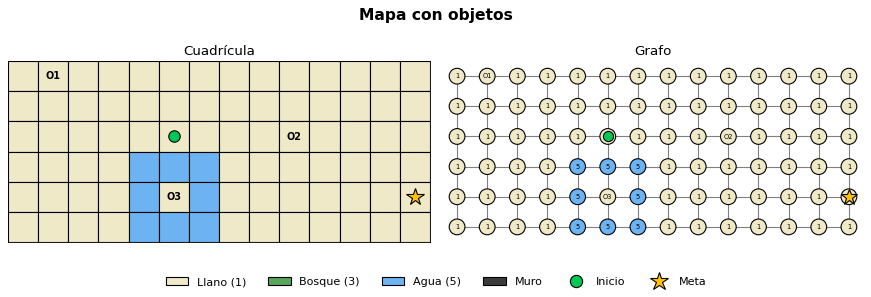

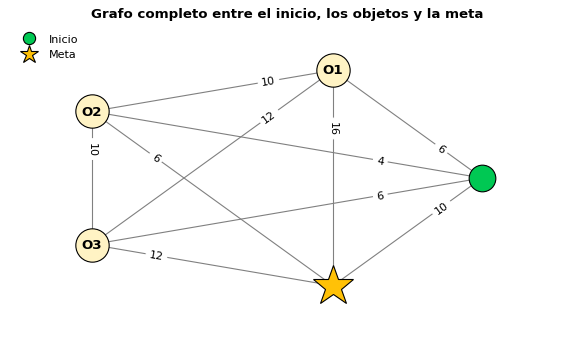

In [22]:
mapa_objetos = leer_mapa("""
.O............
..............
.....I...O....
....AAA.......
....AOA......M
....AAA.......
""")

mostrar_mapa(mapa_objetos, 'Mapa con objetos')

# Los pesos del grafo completo: la ruta más barata entre cada par de puntos.
tabla = costos_entre_puntos(mapa_objetos)

# Una figura con un solo dibujo para el grafo completo.
figura, eje = plt.subplots(figsize=(9, 5))
dibujar_grafo_completo(eje, mapa_objetos, tabla)
eje.set_title('Grafo completo entre el inicio, los objetos y la meta', fontweight='bold')
plt.show()

El grafo completo tiene 5 vértices (el inicio, 3 objetos y la meta) y 10 aristas, una por cada par de vértices.

Conviene fijarse en la arista entre el inicio y `O3`. En línea recta están a 2 casillas, pero la arista pesa 6, porque para llegar hay que cruzar agua. En cambio `O2` está a 4 casillas y su arista pesa 4. Midiendo por el costo de la ruta, el objeto más cercano al inicio es `O2`, no `O3`.

Probar todos los órdenes: inicio -> O1 -> O3 -> O2 -> meta   costo 34   (6 órdenes revisados)
Ir siempre al más cercano: inicio -> O2 -> O1 -> O3 -> meta   costo 38   (1 orden construido)
Comprobado con NetworkX: los pesos del grafo completo son los costos mínimos.


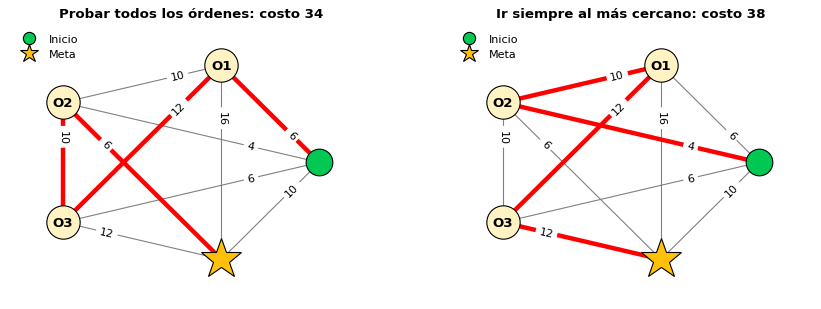

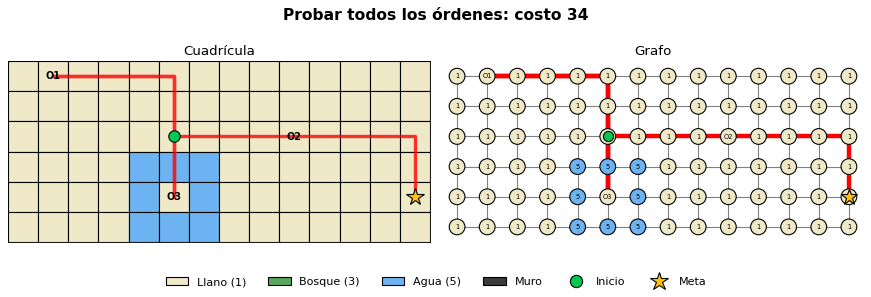

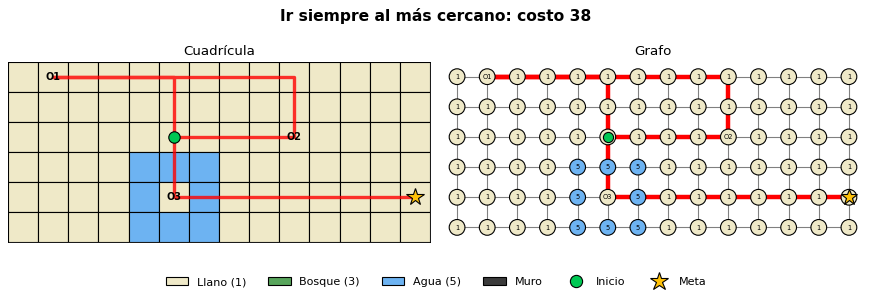

In [23]:
# Las dos estrategias sobre el mismo mapa.
orden_optimo, costo_optimo, revisados = todos_los_ordenes(mapa_objetos, tabla)
orden_cercano, costo_cercano = mas_cercano(mapa_objetos, tabla)

print(f'Probar todos los órdenes: {nombres_del_orden(mapa_objetos, orden_optimo)}   '
      f'costo {costo_optimo}   ({revisados} órdenes revisados)')
print(f'Ir siempre al más cercano: {nombres_del_orden(mapa_objetos, orden_cercano)}   '
      f'costo {costo_cercano}   (1 orden construido)')

# Comprobación con NetworkX: cada arista del grafo completo pesa el costo mínimo real.
grafo = construir_grafo(mapa_objetos)
for (a, b), (costo, ruta) in tabla.items():
    assert costo == nx.dijkstra_path_length(grafo, a, b)
print('Comprobado con NetworkX: los pesos del grafo completo son los costos mínimos.')

# Los dos caminos elegidos sobre el grafo completo: una figura con dos dibujos lado a lado.
figura, (izquierda, derecha) = plt.subplots(1, 2, figsize=(13, 4.5))
dibujar_grafo_completo(izquierda, mapa_objetos, tabla, orden_optimo)
izquierda.set_title(f'Probar todos los órdenes: costo {costo_optimo}', fontweight='bold')
dibujar_grafo_completo(derecha, mapa_objetos, tabla, orden_cercano)
derecha.set_title(f'Ir siempre al más cercano: costo {costo_cercano}', fontweight='bold')
plt.show()

# Las dos rutas completas sobre el mapa. unir_rutas pega los tramos en una sola ruta.
mostrar_mapa(mapa_objetos, f'Probar todos los órdenes: costo {costo_optimo}',
             ruta=unir_rutas(mapa_objetos, tabla, orden_optimo))
mostrar_mapa(mapa_objetos, f'Ir siempre al más cercano: costo {costo_cercano}',
             ruta=unir_rutas(mapa_objetos, tabla, orden_cercano))

**Qué se observa**

- Probar todos los órdenes encuentra el mejor: `inicio -> O1 -> O3 -> O2 -> meta`, con costo 34.
- Ir siempre al más cercano elige `inicio -> O2 -> O1 -> O3 -> meta`, con costo 38.
- La estrategia del más cercano empieza bien: `O2` es lo más barato desde el inicio. Pero después tiene que cruzar todo el mapa hasta `O1` y regresar. Cada decisión es la mejor en su momento y el total no lo es.
- El mejor orden empieza por `O1`, que **no** es el más cercano: llegar a él cuesta 6, contra 4 de `O2`. Parece mala idea, pero deja los demás objetos en fila rumbo a la meta.

In [24]:
# Cuántos órdenes hay que revisar según el número de objetos.
print(f"{'Objetos':>8}{'Órdenes posibles (n!)':>24}")
for n in range(1, 13):
    print(f'{n:>8}{factorial(n):>24,}')

 Objetos   Órdenes posibles (n!)
       1                       1
       2                       2
       3                       6
       4                      24
       5                     120
       6                     720
       7                   5,040
       8                  40,320
       9                 362,880
      10               3,628,800
      11              39,916,800
      12             479,001,600


Con 3 objetos solo hay 6 órdenes y probarlos todos es inmediato. Con 8 ya son 40,320 y con 12 son casi 480 millones. La estrategia del más cercano, en cambio, con `n` objetos solo toma `n` decisiones.

Por eso se usan las dos: probar todos los órdenes cuando hay pocos objetos y se necesita lo mejor, y una estrategia rápida cuando hay muchos y basta con una respuesta buena. Este problema de visitar varios puntos al menor costo se conoce como el **problema del agente viajero**.

## 7. Un mapa para editar

Cambia el texto de `mi_mapa` y vuelve a ejecutar la celda. Recuerda:

- `.` llano, `B` bosque, `A` agua, `#` muro.
- `I` inicio y `M` meta: uno de cada uno.
- `O` objeto: los que quieras, o ninguno. Si hay objetos, además de comparar los algoritmos se comparan las dos estrategias para recogerlos. Con más de 8 objetos, probar todos los órdenes empieza a tardar.
- Las filas pueden medir distinto.

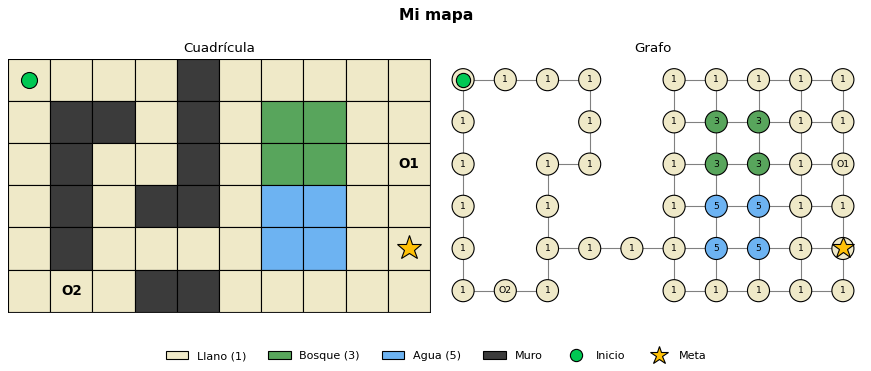

Algoritmo  Exploradas   Pasos   Costo   Nota
----------------------------------------------------
BFS                36      15      23   
DFS                24      23      23   
Dijkstra           37      17      17   costo mínimo
Voraz              16      15      23   
A*                 26      17      17   costo mínimo
Comprobado con NetworkX: rutas válidas, costo mínimo = 17, pasos mínimos = 15.


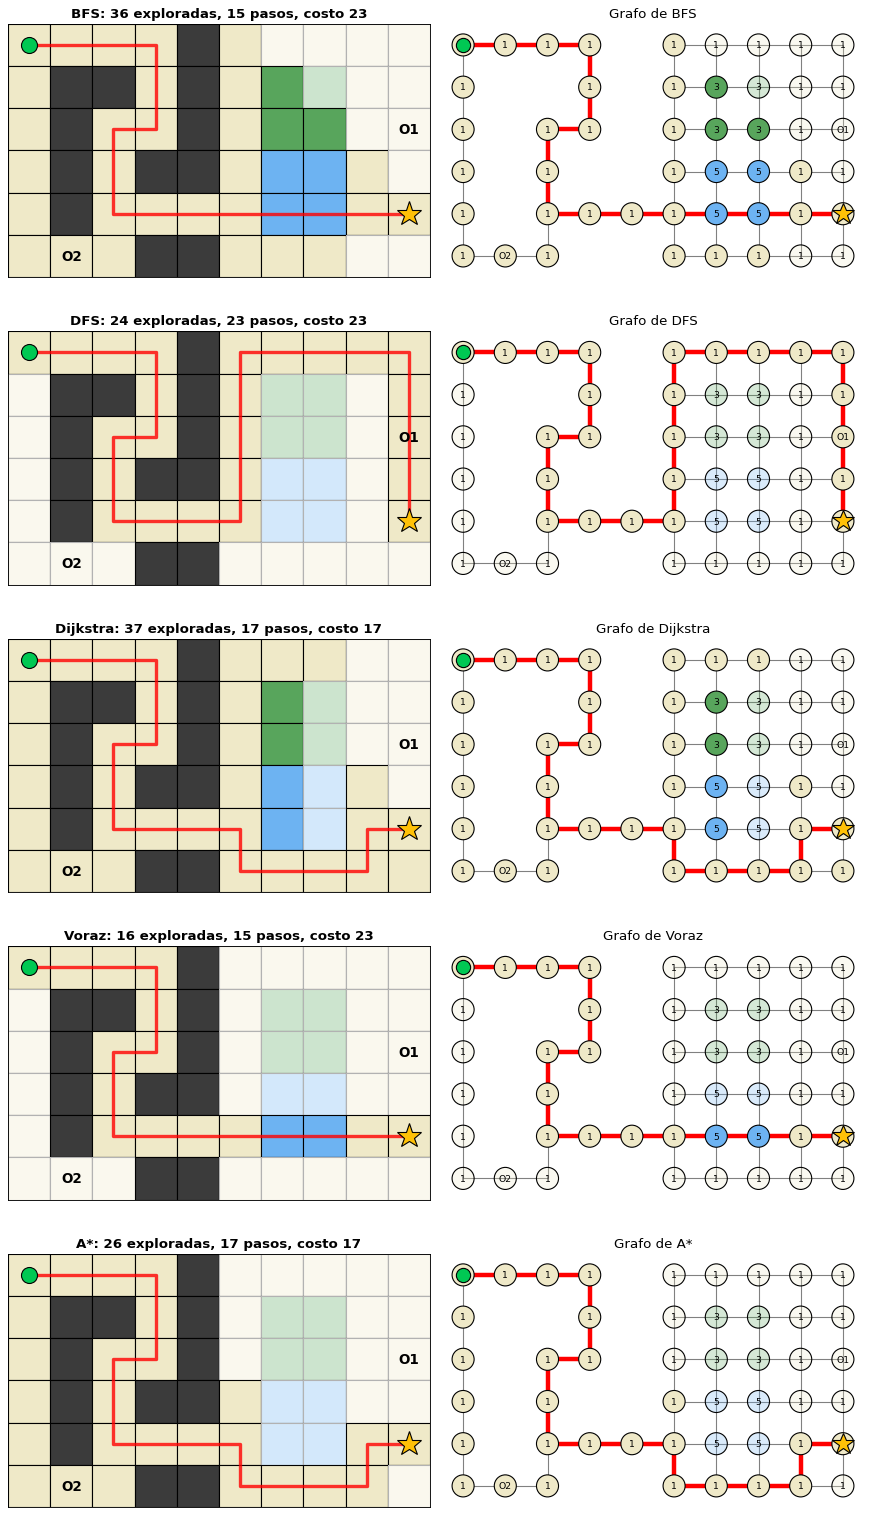

Probar todos los órdenes: inicio -> O2 -> O1 -> meta   costo 21   (2 órdenes revisados)
Ir siempre al más cercano: inicio -> O2 -> O1 -> meta   costo 21


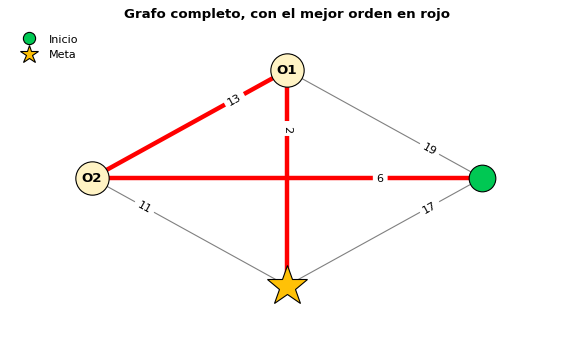

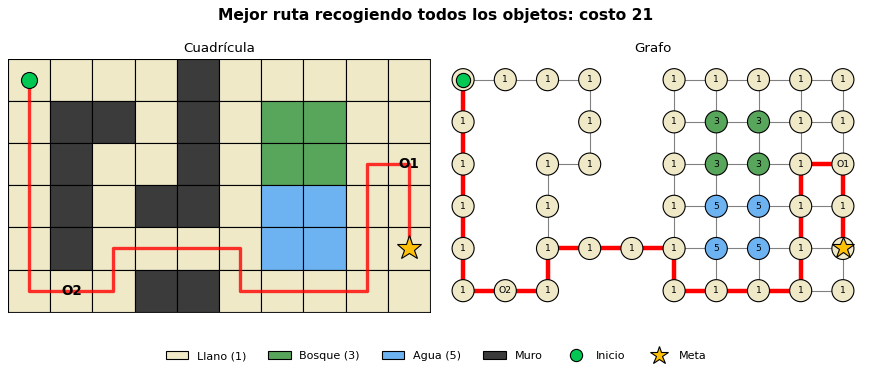

In [25]:
mi_mapa = """
I...#.....
.##.#.BB..
.#..#.BB.O
.#.##.AA..
.#....AA.M
.O.##.....
"""

# Lee el texto y hace el análisis completo de los cinco algoritmos.
mapa = leer_mapa(mi_mapa)
analizar(mapa, 'Mi mapa')

# Si el mapa tiene objetos, se comparan también las dos estrategias para recogerlos.
if mapa['objetos']:
    tabla = costos_entre_puntos(mapa)
    if any(costo is None for costo, ruta in tabla.values()):
        # Algún par de puntos no tiene camino entre sí.
        print('Hay puntos a los que no se puede llegar: no es posible recoger todo y llegar a la meta.')
    else:
        orden_optimo, costo_optimo, revisados = todos_los_ordenes(mapa, tabla)
        orden_cercano, costo_cercano = mas_cercano(mapa, tabla)
        print(f'Probar todos los órdenes: {nombres_del_orden(mapa, orden_optimo)}   '
              f'costo {costo_optimo}   ({revisados} órdenes revisados)')
        print(f'Ir siempre al más cercano: {nombres_del_orden(mapa, orden_cercano)}   costo {costo_cercano}')
        # El grafo completo con el mejor orden marcado en rojo.
        figura, eje = plt.subplots(figsize=(9, 5))
        dibujar_grafo_completo(eje, mapa, tabla, orden_optimo)
        eje.set_title('Grafo completo, con el mejor orden en rojo', fontweight='bold')
        plt.show()
        # La mejor ruta completa sobre el mapa.
        mostrar_mapa(mapa, f'Mejor ruta recogiendo todos los objetos: costo {costo_optimo}',
                     ruta=unir_rutas(mapa, tabla, orden_optimo))

## 8. Criterio de mejor opción

Las tablas anteriores muestran los números de cada algoritmo, pero no dicen cuál conviene. Para decidirlo hace falta una regla fija, que se aplique igual en todos los mapas. La regla es un **puntaje**:

$$\text{puntaje} = \text{costo} \times 10\,000 + \text{casillas exploradas}$$

**Gana el algoritmo con el puntaje más bajo.** Un algoritmo que no encontró ruta no tiene puntaje y no participa. Si varios empatan en el puntaje más bajo, se reportan todos. Si ninguno encontró ruta, no hay ganador.

**Cómo se lee el número.** Las últimas cuatro cifras son las casillas exploradas y las de adelante son el costo. Por ejemplo, `120020` es una ruta de costo 12 encontrada explorando 20 casillas, y `200009` es una ruta de costo 20 encontrada explorando 9.

**Por qué primero la calidad de la ruta y después el esfuerzo de buscar.** La ruta es lo que se va a usar: el personaje la recorre y paga su costo. Las casillas exploradas son el trabajo de encontrarla, que se hace una sola vez. Un algoritmo que explora muy poco pero entrega una ruta más cara no resolvió mejor el problema: resolvió uno más fácil. Por eso el costo ocupa las cifras de la izquierda, que son las que más pesan, y las casillas exploradas solo deciden cuando el costo empata.

**Por qué se multiplica por 10 000.** Para que una diferencia de 1 en el costo pese más que cualquier diferencia posible en casillas exploradas. Bajar el costo en 1 quita 10 000 puntos, y explorar de más nunca alcanza a sumar tanto, porque las casillas exploradas siempre son menos de 10 000. El 10 000 no es una opinión sobre cuánto vale cada medida: solo es el espacio que se aparta para escribir las casillas exploradas. Cualquier número más grande, como 100 000 o un millón, daría el mismo orden y el mismo ganador. Un número chico, como 10, sí cambiaría el resultado, porque entonces explorar de más podría compensar una ruta más cara.

**La idea que el puntaje expresa.** Comparar puntajes es comparar los pares (costo, exploradas) en *orden lexicográfico*, que es el orden del diccionario: dos palabras se comparan por su primera letra y solo si empatan se mira la segunda. Aquí la primera letra es el costo y la segunda son las casillas exploradas. El puntaje escribe ese par como un solo número.

In [26]:
# El costo se multiplica por este número para que quede en las cifras de la izquierda
# del puntaje, y las casillas exploradas en las últimas cuatro. Tiene que ser mayor que
# cualquier cantidad posible de casillas exploradas.
BASE_DEL_PUNTAJE = 10000


def puntaje(resultado):
    """Calcula el puntaje de un algoritmo en un mapa. Mientras más bajo, mejor.

        puntaje = costo * 10 000 + casillas exploradas

    Entrada: el resultado de un algoritmo, uno de los valores del diccionario
             que devuelve comparar. Tiene 'ruta', 'exploradas', 'pasos' y 'costo'.

    Salida: el puntaje, un número entero. None si el algoritmo no encontró ruta.
    """
    if resultado['ruta'] is None:
        return None                                  # sin ruta no hay puntaje: no participa
    exploradas = len(resultado['exploradas'])
    if exploradas >= BASE_DEL_PUNTAJE:
        # Con tantas casillas el número se desbordaría hacia las cifras del costo.
        raise ValueError(f'El puntaje solo sirve con menos de {BASE_DEL_PUNTAJE} casillas exploradas.')
    return resultado['costo'] * BASE_DEL_PUNTAJE + exploradas


def mejor_opcion(resultados):
    """Elige la mejor opción de un mapa: el algoritmo con el puntaje más bajo.

    Entrada: el diccionario que devuelve comparar.

    Salida: lista con los nombres de los ganadores.
            Normalmente trae uno solo. Trae varios si empatan en puntaje, y
            queda vacía si ningún algoritmo encontró ruta.
    """
    # El puntaje de cada algoritmo que sí encontró ruta.
    puntajes = {nombre: puntaje(r) for nombre, r in resultados.items() if r['ruta'] is not None}
    if not puntajes:
        return []                                    # no existe ruta: no hay ganador
    mas_bajo = min(puntajes.values())
    return [nombre for nombre, valor in puntajes.items() if valor == mas_bajo]

### El puntaje en todos los mapas

Se calcula el puntaje de cada algoritmo en cada mapa del notebook, incluido el de la sección 7. En el mapa con objetos se compara la búsqueda del inicio a la meta, igual que en los demás. Un guion significa que el algoritmo no encontró ruta.

In [27]:
# Todos los mapas del notebook con su nombre. El último es el de la sección 7:
# si se edita y se vuelve a ejecutar, su renglón cambia.
todos_los_mapas = {'Forma irregular': ejemplo, 'Campo abierto': mapa_abierto,
                   'Terrenos mezclados': mapa_terrenos, 'Laberinto': mapa_laberinto,
                   'Sin solución': mapa_sin_solucion, 'Con objetos': mapa_objetos, 'Mi mapa': mapa}

# Cada columna tiene un ancho fijo y va separada de la siguiente por una barra.
# En el formato, :<18 alinea a la izquierda en 18 espacios y :>8 a la derecha en 8.
renglon = ' {:<18} |' + ' {:>8} |' * len(ALGORITMOS) + ' {}'
print(renglon.format('Mapa', *ALGORITMOS, 'Ganador'))                # el * reparte los cinco nombres en sus columnas
print('-' * 20 + ('+' + '-' * 10) * len(ALGORITMOS) + '+' + '-' * 20)   # raya con un cruce bajo cada barra

for nombre_mapa, un_mapa in todos_los_mapas.items():
    resultados = comparar(un_mapa)
    # El puntaje de cada algoritmo, o un guion si no encontró ruta.
    puntajes = [puntaje(r) if r['ruta'] is not None else '-' for r in resultados.values()]
    ganadores = mejor_opcion(resultados)
    ganador = ', '.join(ganadores) if ganadores else 'ninguno (sin ruta)'
    print(renglon.format(nombre_mapa, *puntajes, ganador))

 Mapa               |      BFS |      DFS | Dijkstra |    Voraz |       A* | Ganador
--------------------+----------+----------+----------+----------+----------+--------------------
 Forma irregular    |   120018 |   120011 |    80016 |   120011 |    80009 | A*
 Campo abierto      |   130084 |   190020 |   130084 |   130014 |   130014 | Voraz, A*
 Terrenos mezclados |   200053 |   220023 |   120059 |   200009 |   120020 | A*
 Laberinto          |   160047 |   240030 |   160046 |   160019 |   160029 | Voraz
 Sin solución       |        - |        - |        - |        - |        - | ninguno (sin ruta)
 Con objetos        |   100082 |   140015 |   100079 |   100011 |   100011 | Voraz, A*
 Mi mapa            |   230036 |   230024 |   170037 |   230016 |   170026 | A*


**Qué se observa**

- El ganador de cada mapa es el del puntaje más bajo de su renglón. De los 6 mapas que tienen ruta, A\* gana solo en 3 y empata con el voraz en 2.
- En terrenos mezclados se ve cómo manda el costo: el voraz explora solo 9 casillas, pero su ruta cuesta 20 y su puntaje es `200009`. A\* explora más, 20 casillas, con una ruta de costo 12: su puntaje es `120020`, mucho más bajo.
- En el mismo mapa, Dijkstra y A\* empatan en costo y los separan las últimas cifras: `120059` contra `120020`.
- En el laberinto gana el voraz, `160019` contra `160029` de A\*: llegó al mismo costo mínimo explorando menos casillas.
- Dijkstra tiene siempre las mismas cifras de adelante que el ganador, porque garantiza el costo mínimo, pero en estos mapas nunca gana: explora más que A\*.
- En el mapa sin solución nadie tiene puntaje y no hay ganador.

Estos números corresponden a los mapas tal como vienen en el notebook. El renglón de "Mi mapa" cambia si se edita la sección 7.

## 9. Aplicaciones

Cada algoritmo sirve para aquello que garantiza. La tabla reúne, de forma general, un uso en videojuegos y otro fuera de ellos.

| Algoritmo | En videojuegos | Fuera de los videojuegos |
| --- | --- | --- |
| BFS | Relleno por inundación, como destapar de una vez las casillas vacías en un juego tipo Buscaminas, y mapas de distancia en juegos de defender torres | El menor número de saltos entre dos puntos de una red |
| DFS | Generar laberintos y revisar que un mapa siga conectado | Detectar ciclos y revisar dependencias |
| Dijkstra | El alcance de movimiento de una unidad en juegos por turnos | Navegación por GPS y enrutamiento en redes de computadoras |
| Voraz | Enemigos que persiguen eligiendo siempre la casilla que parece más cerca de su objetivo | Decisiones rápidas donde basta una ruta aceptable |
| A\* | Movimiento de unidades y personajes en juegos de estrategia y de rol | Robots móviles y rutas de evacuación |

Cada uso se sigue de lo que se midió en este notebook:

- **BFS** explora por capas y deja a cada casilla con su número de pasos desde el origen. Sirve cuando todos los pasos cuestan lo mismo o cuando se quiere tocar todo lo alcanzable.
- **DFS** no promete una buena ruta (en campo abierto dio 19 pasos contra 13), pero recorre todo lo que está conectado con una simple pila. Sirve cuando la pregunta no es por dónde ir, sino si se puede llegar.
- **Dijkstra** explora en todas direcciones todo lo que cuesta menos que la meta. Para una sola ruta es trabajo de más (84 casillas contra 14 de A\* en campo abierto), y es justo lo que hace falta cuando se quiere el costo hacia muchos destinos a la vez.
- **El voraz** responde explorando muy poco (9 casillas en terrenos mezclados), pero pagó 20 en lugar de 12. Sirve cuando una ruta imperfecta es aceptable.
- **A\*** da el costo mínimo y explora menos que Dijkstra. Sirve cuando se quiere la mejor ruta hacia un solo destino.

**Dentro de este proyecto.** Algunas de estas ideas se usan en los juegos de la fase 3 (`fase3_juegos.py`):

- El laberinto de Maze Runner se genera con un recorrido en profundidad al azar: se avanza abriendo paso hacia celdas no visitadas y, al llegar a un callejón, se regresa una celda. El camino recorrido se guarda en una pila.
- Antes de cerrar un pasillo de ese laberinto se comprueba, con un recorrido que también usa una pila, que todas las celdas siguen conectadas. Si alguna queda aislada, el pasillo se vuelve a abrir.
- Al sortear el terreno de atrapa gemas y de captura la bandera se corre BFS con una meta que no existe. Así se obtiene todo lo alcanzable, que es un relleno por inundación, y se confirma que nadie queda encerrado.
- Para saber qué competidor va más cerca de la salida de Maze Runner se corre Dijkstra una sola vez, saliendo de la salida, y se obtiene el costo desde todas las casillas: un mapa de distancia que toma en cuenta el terreno.

### El caso de la evacuación

Encontrar la salida de un edificio durante una emergencia tiene la misma forma que los mapas de este notebook. Los muros son las paredes. El terreno caro son las zonas con humo o con aglomeración: se pueden cruzar, pero conviene evitarlas, igual que el agua y el bosque. Un pasillo que se bloquea cambia el grafo y obliga a calcular la ruta otra vez. Y la respuesta tiene que darse al instante, así que también importa cuánto trabaja el algoritmo.

Con los resultados de las secciones anteriores, el que convendría es A\*:

- BFS no sirve, porque no ve los costos. En terrenos mezclados encontró la ruta de menos pasos (8) y pagó 20: sería la ruta más corta, cruzando el humo.
- El voraz es el más rápido, pero no es confiable. En ese mismo mapa exploró solo 9 casillas y también pagó 20 en lugar de 12. En una evacuación, una ruta que se ve directa y atraviesa la zona peligrosa es justo el error que no se puede cometer.
- Dijkstra y A\* dan siempre el costo mínimo, comprobado con NetworkX en todos los mapas. La diferencia está en el trabajo: A\* exploró 14 casillas contra 84 en campo abierto, 20 contra 59 en terrenos mezclados y 29 contra 46 en el laberinto. Si cada bloqueo obliga a recalcular, ese ahorro se repite en cada cálculo.

Hay dos reservas. La primera: un edificio se parece más al laberinto que al campo abierto, y ahí la ventaja de A\* fue la más chica, porque las paredes obligan a alejarse de la salida y la estimación orienta menos. La segunda: si un bloqueo deja a alguien sin salida, ningún algoritmo lo descubre más rápido que otro. En el mapa sin solución los cinco revisaron las mismas 51 casillas.

Estos experimentos se hicieron en mapas de juego pequeños, no en planos de edificios reales. Lo que muestran es por qué A\* sería el punto de partida razonable, no qué tan bien funcionaría en un caso real.

## 10. Conclusiones

**Un mapa de cuadrícula es un grafo.** Las casillas son los vértices, los movimientos son las aristas y el costo del terreno es el peso. Con esa idea, encontrar un camino en un videojuego se vuelve un problema de búsqueda en grafos.

**Los cinco algoritmos hacen lo mismo y solo cambian en qué casilla sale primero.**

| Algoritmo | Qué sale primero | Ruta que encuentra | Cuánto explora |
| --- | --- | --- | --- |
| BFS | La más antigua (cola) | La de menos pasos | Mucho |
| DFS | La más reciente (pila) | Cualquiera, suele ser mala | Depende de la suerte |
| Dijkstra | La de menor costo acumulado | La de menor costo | Mucho |
| Voraz | La que parece más cerca de la meta | Sin garantía | Muy poco |
| A\* | La de menor costo acumulado más estimación | La de menor costo | Poco |

**Menos pasos no es menos costo.** En el mapa de terrenos mezclados, BFS encontró la ruta de menos pasos (8) y pagó 20. Dijkstra y A\* dieron 12 pasos y pagaron 12.

**A\* llega a la misma ruta barata que Dijkstra explorando menos.** En campo abierto exploró 14 casillas contra 84, y en terrenos mezclados 20 contra 59. Funciona porque su estimación nunca se pasa del costo real: cada paso cuesta al menos 1, así que la distancia en casillas nunca exagera lo que falta. Con una estimación que no exagera, A\* nunca descarta la ruta más barata.

**El voraz usa la misma estimación y sí se equivoca,** porque no toma en cuenta lo que ya gastó. Explora muy poco, pero cruzó el lago y pagó 20 en lugar de 12.

**Cuando no hay camino, todos trabajan lo mismo.** Hay que revisar todo lo alcanzable para estar seguro.

**Con objetos, el problema cambia de tamaño.** Entre el inicio, los objetos y la meta se forma un grafo completo, y hay que elegir el orden de visita. Probar todos los órdenes da siempre el mejor, pero la cantidad de órdenes crece como `n!`. Ir siempre al más cercano es inmediato y no siempre acierta: en el ejemplo pagó 38 en lugar de 34.

**Con el criterio de mejor opción, A\* es el que más veces queda arriba, pero no siempre.** De los 6 mapas con ruta ganó solo en 3 y empató con el voraz en 2; en el laberinto ganó el voraz, que esa vez llegó al costo mínimo explorando menos. Son pocos mapas y pequeños: muestran una tendencia, no una regla general.

**Para un videojuego,** A\* es la mejor opción cuando importa la calidad de la ruta: da la más barata y trabaja mucho menos que Dijkstra. El voraz sirve cuando lo que importa es responder rápido y una ruta imperfecta es aceptable.